STARTING GRIDWORLD EXPERIMENT

Training: Sparse Q-Learning
Sparse Q-Learning completed.          

Training: Fixed PBRS
Fixed PBRS completed.          

Training: Adaptive PBRS
Adaptive PBRS completed.          


FINAL RESULTS - LAST 100 EPISODES


,Method,Success Rate (%),Success SD,Average Reward,Average Steps to Goal
0,Sparse Q-Learning,100.0,0.0,7.39,19.04
1,Fixed PBRS,100.0,0.0,7.36,19.06
2,Adaptive PBRS,100.0,0.0,7.39,20.07


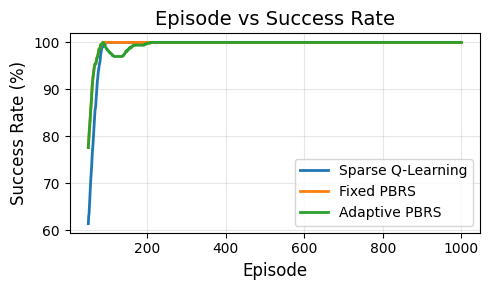

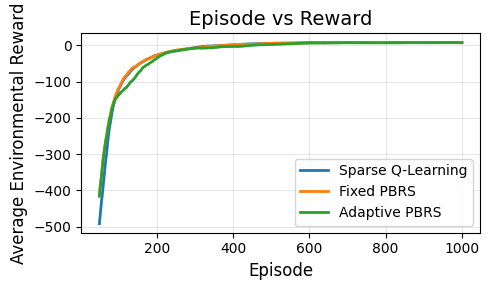

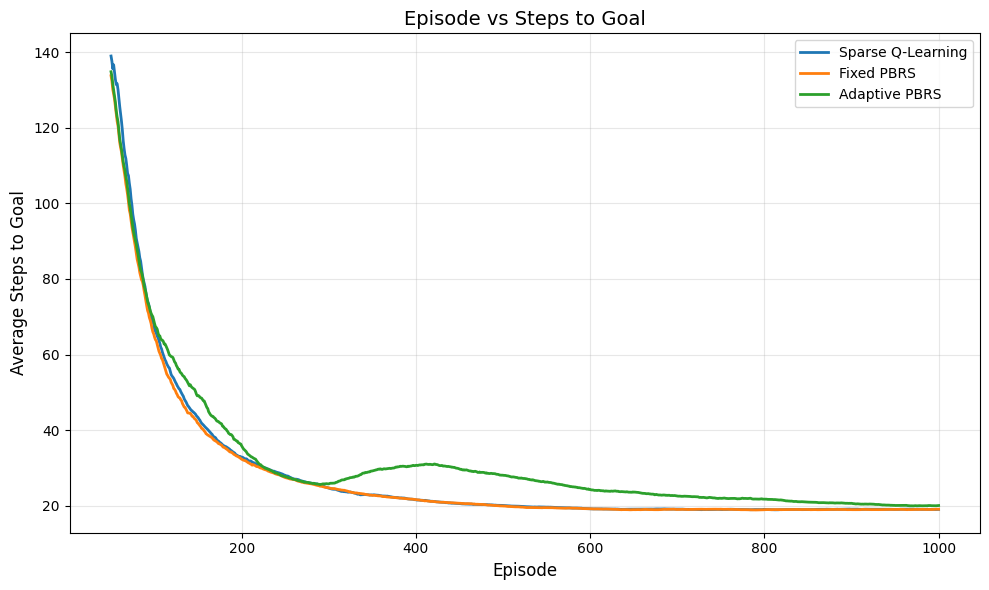

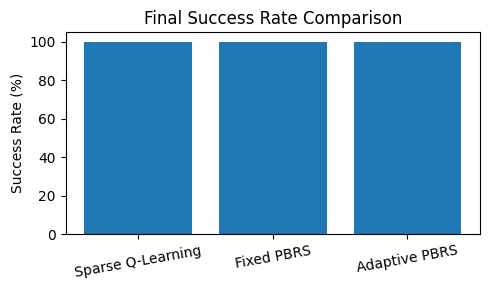

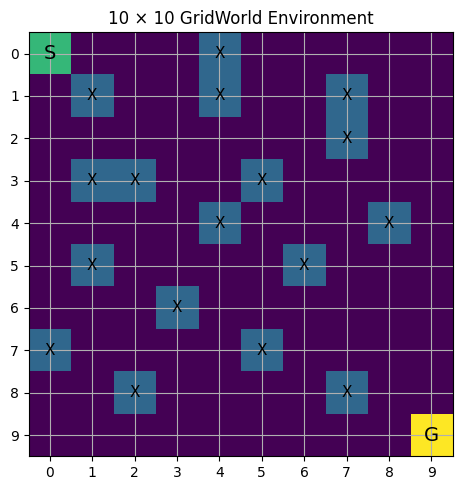



EXPERIMENT COMPLETED SUCCESSFULLY

Generated files:
1. gridworld_success_rate.png
2. gridworld_reward.png
3. gridworld_steps.png
4. final_success_comparison.png
5. gridworld_environment.png
6. gridworld_experiment_summary.csv

Final Results:
           Method  Success Rate (%)  Success SD  Average Reward  Average Steps to Goal
Sparse Q-Learning             100.0         0.0            7.39                  19.04
       Fixed PBRS             100.0         0.0            7.36                  19.06
    Adaptive PBRS             100.0         0.0            7.39                  20.07


In [ ]:
# ============================================================
# RESEARCH EXPERIMENT
# Adaptive Potential-Based Reward Shaping for Q-Learning
# in Sparse-Reward GridWorld Environments
#
# Google Colab compatible - paste this entire code in ONE cell
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. EXPERIMENT SETTINGS
# ============================================================

GRID = 10

START = (0, 0)
GOAL = (9, 9)

# Obstacles inside GridWorld
OBSTACLES = {
    (0, 4),
    (1, 1), (1, 4), (1, 7),
    (2, 7),
    (3, 1), (3, 2), (3, 5),
    (4, 4), (4, 8),
    (5, 1), (5, 6),
    (6, 3),
    (7, 0), (7, 5),
    (8, 2), (8, 7)
}

# Actions:
# 0 = UP
# 1 = DOWN
# 2 = LEFT
# 3 = RIGHT

ACTIONS = [
    (-1, 0),   # Up
    (1, 0),    # Down
    (0, -1),   # Left
    (0, 1)     # Right
]


# ============================================================
# 2. Q-LEARNING PARAMETERS
# ============================================================

N_EPISODES = 1000
N_SEEDS = 10

MAX_STEPS = 250

ALPHA = 0.1
GAMMA = 0.95

EPS_START = 1.0
EPS_MIN = 0.05
EPS_DECAY = 0.995

# Reward shaping parameters
LAMBDA0 = 1.0
K = 0.005


# ============================================================
# 3. POTENTIAL FUNCTION
# ============================================================

def phi(state):

    """
    Potential function based on Manhattan distance.

    States closer to goal have higher potential.
    """

    row, col = state

    distance = (
        abs(row - GOAL[0])
        +
        abs(col - GOAL[1])
    )

    return -distance


# ============================================================
# 4. GRIDWORLD ENVIRONMENT
# ============================================================

def environment_step(state, action):

    dr, dc = ACTIONS[action]

    new_row = state[0] + dr
    new_col = state[1] + dc

    # ----------------------------------------
    # Boundary collision
    # ----------------------------------------

    if (
        new_row < 0
        or new_row >= GRID
        or new_col < 0
        or new_col >= GRID
    ):

        return state, -10.0, False


    new_state = (new_row, new_col)


    # ----------------------------------------
    # Obstacle collision
    # ----------------------------------------

    if new_state in OBSTACLES:

        return state, -10.0, False


    # ----------------------------------------
    # Goal reached
    # ----------------------------------------

    if new_state == GOAL:

        return new_state, 10.0, True


    # ----------------------------------------
    # Normal movement = sparse reward
    # ----------------------------------------

    return new_state, 0.0, False


# ============================================================
# 5. Q-LEARNING TRAINING FUNCTION
# ============================================================

def train(method, seed):

    # Random generator
    rng = np.random.default_rng(seed)

    # Q-table
    Q = np.zeros((GRID, GRID, 4))

    episode_rewards = []
    episode_success = []
    episode_steps = []

    epsilon = EPS_START


    # ========================================================
    # TRAINING LOOP
    # ========================================================

    for episode in range(N_EPISODES):

        state = START

        total_environment_reward = 0.0

        success = 0

        steps_used = np.nan


        # ----------------------------------------------------
        # One episode
        # ----------------------------------------------------

        for step_number in range(MAX_STEPS):

            # =================================================
            # EPSILON-GREEDY ACTION SELECTION
            # =================================================

            if rng.random() < epsilon:

                action = rng.integers(4)

            else:

                q_values = Q[
                    state[0],
                    state[1]
                ]

                # Random tie-breaking
                best_actions = np.flatnonzero(
                    q_values == q_values.max()
                )

                action = rng.choice(best_actions)


            # =================================================
            # TAKE ACTION
            # =================================================

            next_state, reward, done = environment_step(
                state,
                action
            )

            total_environment_reward += reward


            # =================================================
            # METHOD 1:
            # SPARSE Q-LEARNING
            # =================================================

            if method == "Sparse Q-Learning":

                learning_reward = reward


            # =================================================
            # REWARD SHAPING METHODS
            # =================================================

            else:

                # Potential-based shaping:
                #
                # F(s,s') = gamma * Phi(s') - Phi(s)

                shaping_reward = (
                    GAMMA * phi(next_state)
                    -
                    phi(state)
                )


                # =============================================
                # METHOD 2:
                # FIXED PBRS
                # =============================================

                if method == "Fixed PBRS":

                    lambda_value = LAMBDA0


                # =============================================
                # METHOD 3:
                # ADAPTIVE PBRS
                # =============================================

                elif method == "Adaptive PBRS":

                    lambda_value = (
                        LAMBDA0
                        *
                        np.exp(-K * episode)
                    )


                learning_reward = (
                    reward
                    +
                    lambda_value * shaping_reward
                )


            # =================================================
            # Q-LEARNING UPDATE
            # =================================================

            if done:

                target = learning_reward

            else:

                target = (
                    learning_reward
                    +
                    GAMMA
                    *
                    np.max(
                        Q[
                            next_state[0],
                            next_state[1]
                        ]
                    )
                )


            Q[
                state[0],
                state[1],
                action
            ] += ALPHA * (
                target
                -
                Q[
                    state[0],
                    state[1],
                    action
                ]
            )


            state = next_state


            # =================================================
            # CHECK GOAL
            # =================================================

            if done:

                success = 1

                steps_used = step_number + 1

                break


        # ====================================================
        # SAVE EPISODE RESULTS
        # ====================================================

        episode_rewards.append(
            total_environment_reward
        )

        episode_success.append(
            success
        )

        episode_steps.append(
            steps_used
        )


        # ====================================================
        # EPSILON DECAY
        # ====================================================

        epsilon = max(
            EPS_MIN,
            epsilon * EPS_DECAY
        )


    return (
        np.array(episode_rewards),
        np.array(episode_success),
        np.array(episode_steps)
    )


# ============================================================
# 6. METHODS TO COMPARE
# ============================================================

methods = [

    "Sparse Q-Learning",

    "Fixed PBRS",

    "Adaptive PBRS"

]


# ============================================================
# 7. RUN EXPERIMENTS
# ============================================================

all_results = {}


print("=" * 60)
print("STARTING GRIDWORLD EXPERIMENT")
print("=" * 60)


for method in methods:

    print("\nTraining:", method)

    runs = []

    for seed in range(N_SEEDS):

        print(
            f"Seed {seed + 1}/{N_SEEDS}",
            end="\r"
        )

        result = train(
            method,
            seed
        )

        runs.append(result)


    all_results[method] = {

        "reward":
            np.vstack(
                [run[0] for run in runs]
            ),

        "success":
            np.vstack(
                [run[1] for run in runs]
            ),

        "steps":
            np.vstack(
                [run[2] for run in runs]
            )
    }


    print(
        f"{method} completed.          "
    )


# ============================================================
# 8. CALCULATE FINAL RESULTS
# ============================================================

rows = []


for method in methods:

    data = all_results[method]


    # --------------------------------------------------------
    # Last 100 episodes
    # --------------------------------------------------------

    final_success_per_seed = (
        np.mean(
            data["success"][:, -100:],
            axis=1
        )
        * 100
    )


    final_reward_per_seed = np.mean(
        data["reward"][:, -100:],
        axis=1
    )


    final_steps_per_seed = np.nanmean(
        data["steps"][:, -100:],
        axis=1
    )


    rows.append({

        "Method":
            method,

        "Success Rate (%)":
            round(
                final_success_per_seed.mean(),
                2
            ),

        "Success SD":
            round(
                final_success_per_seed.std(ddof=1),
                2
            ),

        "Average Reward":
            round(
                final_reward_per_seed.mean(),
                2
            ),

        "Average Steps to Goal":
            round(
                final_steps_per_seed.mean(),
                2
            )
    })


summary = pd.DataFrame(rows)


# ============================================================
# 9. DISPLAY RESULTS TABLE
# ============================================================

print("\n")
print("=" * 70)
print("FINAL RESULTS - LAST 100 EPISODES")
print("=" * 70)

display(summary)


# ============================================================
# 10. MOVING AVERAGE FUNCTION
# ============================================================

def moving_average(data, window=50):

    return np.convolve(
        data,
        np.ones(window) / window,
        mode="valid"
    )


episodes = np.arange(
    50,
    N_EPISODES + 1
)


# ============================================================
# 11. GRAPH 1:
# EPISODE VS SUCCESS RATE
# ============================================================

plt.figure(figsize=(5, 3))


for method in methods:

    mean_success = (
        np.mean(
            all_results[method]["success"],
            axis=0
        )
        * 100
    )

    smooth_success = moving_average(
        mean_success,
        50
    )

    plt.plot(
        episodes,
        smooth_success,
        label=method,
        linewidth=2
    )


plt.xlabel(
    "Episode",
    fontsize=12
)

plt.ylabel(
    "Success Rate (%)",
    fontsize=12
)

plt.title(
    "Episode vs Success Rate",
    fontsize=14
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "gridworld_success_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. GRAPH 2:
# EPISODE VS ENVIRONMENTAL REWARD
# ============================================================

plt.figure(figsize=(5, 3))


for method in methods:

    mean_reward = np.mean(
        all_results[method]["reward"],
        axis=0
    )

    smooth_reward = moving_average(
        mean_reward,
        50
    )

    plt.plot(
        episodes,
        smooth_reward,
        label=method,
        linewidth=2
    )


plt.xlabel(
    "Episode",
    fontsize=12
)

plt.ylabel(
    "Average Environmental Reward",
    fontsize=12
)

plt.title(
    "Episode vs Reward",
    fontsize=14
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "gridworld_reward.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. GRAPH 3:
# EPISODE VS STEPS TO GOAL
# ============================================================

plt.figure(figsize=(10, 6))


for method in methods:

    # Average across seeds, ignoring failed episodes
    with np.errstate(all="ignore"):
        mean_steps = np.nanmean(
            all_results[method]["steps"],
            axis=0
        )

    # Fill any NaN values for plotting
    series = pd.Series(mean_steps)

    mean_steps_clean = (
        series
        .interpolate(limit_direction="both")
        .to_numpy()
    )

    smooth_steps = moving_average(
        mean_steps_clean,
        50
    )

    plt.plot(
        episodes,
        smooth_steps,
        label=method,
        linewidth=2
    )


plt.xlabel(
    "Episode",
    fontsize=12
)

plt.ylabel(
    "Average Steps to Goal",
    fontsize=12
)

plt.title(
    "Episode vs Steps to Goal",
    fontsize=14
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "gridworld_steps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. BAR GRAPH:
# FINAL SUCCESS RATE
# ============================================================

plt.figure(figsize=(5, 3))


plt.bar(
    summary["Method"],
    summary["Success Rate (%)"]
)


plt.ylabel(
    "Success Rate (%)"
)

plt.title(
    "Final Success Rate Comparison"
)

plt.ylim(
    0,
    105
)

plt.xticks(
    rotation=10
)

plt.tight_layout()

plt.savefig(
    "final_success_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 15. SAVE RESULTS TO CSV
# ============================================================

summary.to_csv(
    "gridworld_experiment_summary.csv",
    index=False
)


# ============================================================
# 16. DISPLAY GRIDWORLD
# ============================================================

grid_visual = np.zeros(
    (GRID, GRID)
)

for obstacle in OBSTACLES:

    grid_visual[
        obstacle[0],
        obstacle[1]
    ] = 1


grid_visual[
    START[0],
    START[1]
] = 2


grid_visual[
    GOAL[0],
    GOAL[1]
] = 3


plt.figure(figsize=(5, 5))

plt.imshow(
    grid_visual
)

plt.title(
    "10 × 10 GridWorld Environment"
)

plt.xticks(
    range(GRID)
)

plt.yticks(
    range(GRID)
)

plt.grid()


# Add labels
for i in range(GRID):

    for j in range(GRID):

        if (i, j) == START:

            plt.text(
                j,
                i,
                "S",
                ha="center",
                va="center",
                fontsize=14
            )

        elif (i, j) == GOAL:

            plt.text(
                j,
                i,
                "G",
                ha="center",
                va="center",
                fontsize=14
            )

        elif (i, j) in OBSTACLES:

            plt.text(
                j,
                i,
                "X",
                ha="center",
                va="center",
                fontsize=11
            )


plt.tight_layout()

plt.savefig(
    "gridworld_environment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 17. FINAL MESSAGE
# ============================================================

print("\n")
print("=" * 70)
print("EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nGenerated files:")

print("1. gridworld_success_rate.png")
print("2. gridworld_reward.png")
print("3. gridworld_steps.png")
print("4. final_success_comparison.png")
print("5. gridworld_environment.png")
print("6. gridworld_experiment_summary.csv")

print("\nFinal Results:")

print(summary.to_string(index=False))

EXPERIMENT 2: HARD SPARSE-REWARD GRIDWORLD

Training: Sparse Q-Learning
Sparse Q-Learning completed.          

Training: Fixed PBRS
Fixed PBRS completed.          

Training: Adaptive PBRS
Adaptive PBRS completed.          


FINAL RESULTS - EXPERIMENT 2


,Method,Final Success Rate (%),Success SD,Final Average Reward,Average Steps to Goal,Episodes to 90% Success
0,Sparse Q-Learning,100.00,0.00,1.000,41.30,385.40
1,Fixed PBRS,33.25,46.17,0.332,168.17,2022.86
2,Adaptive PBRS,40.12,50.16,0.401,127.50,772.00


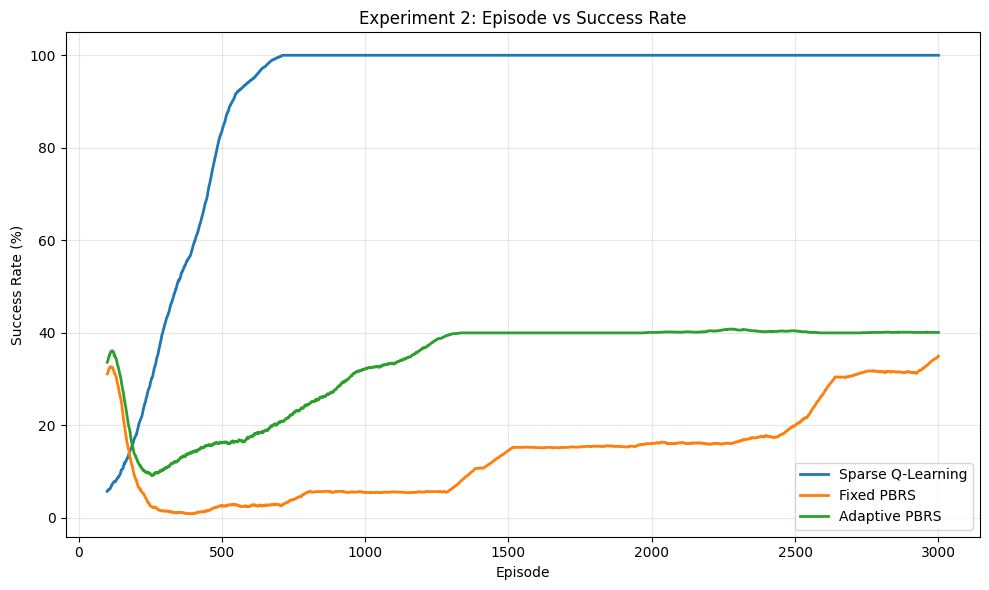

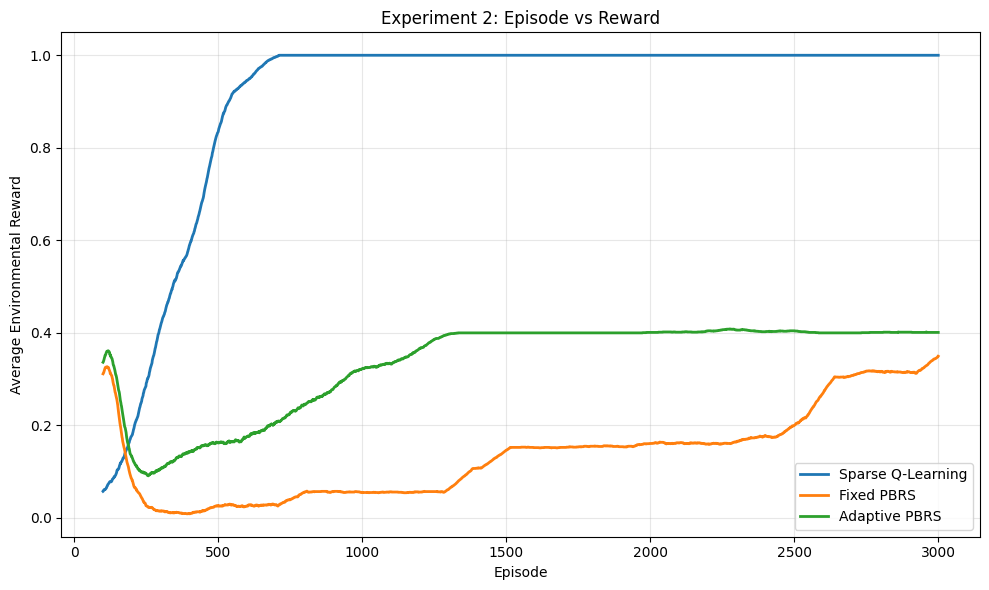

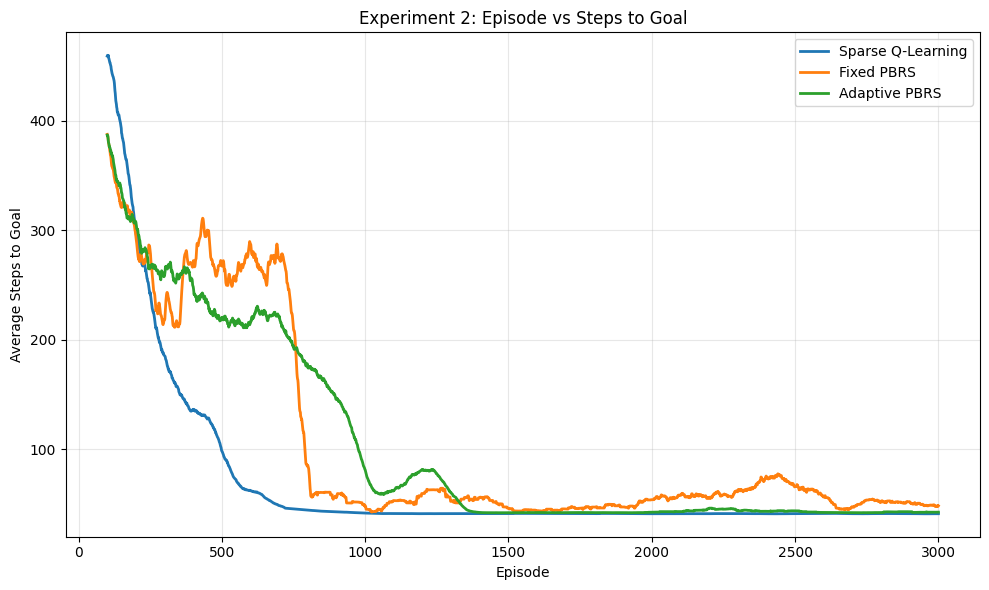

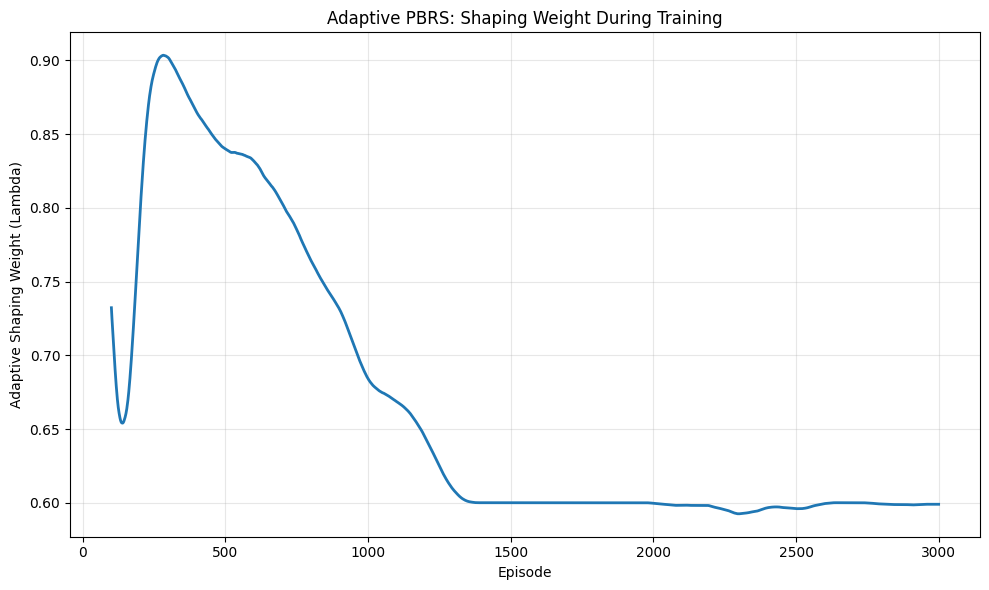

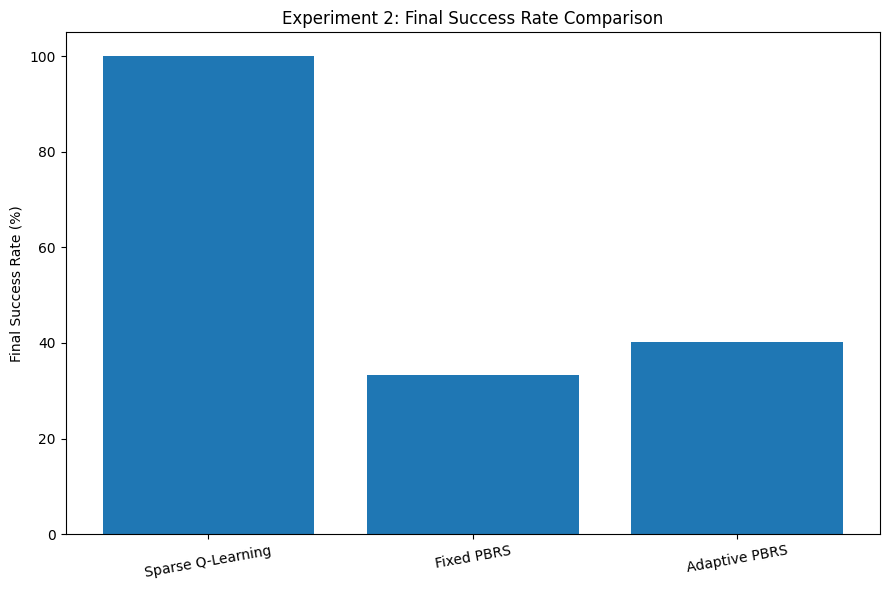

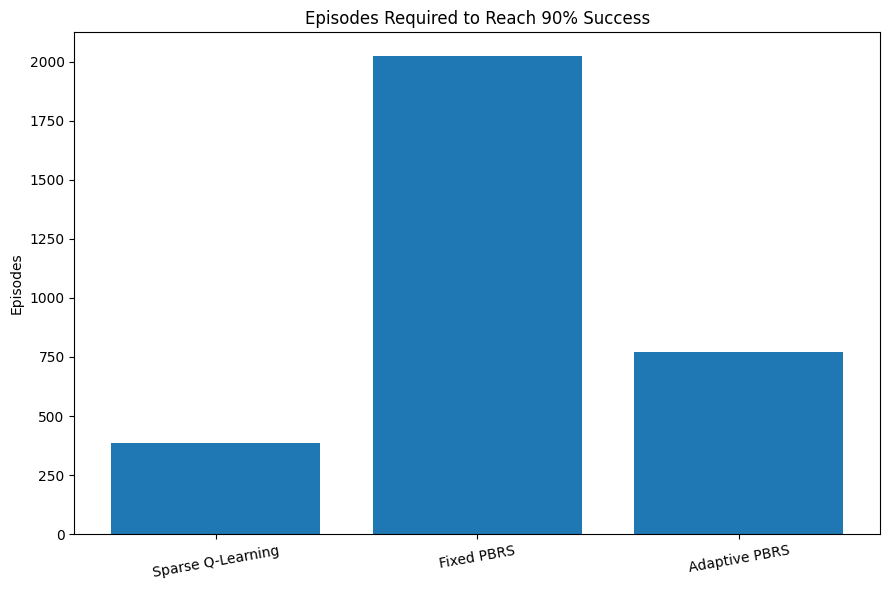

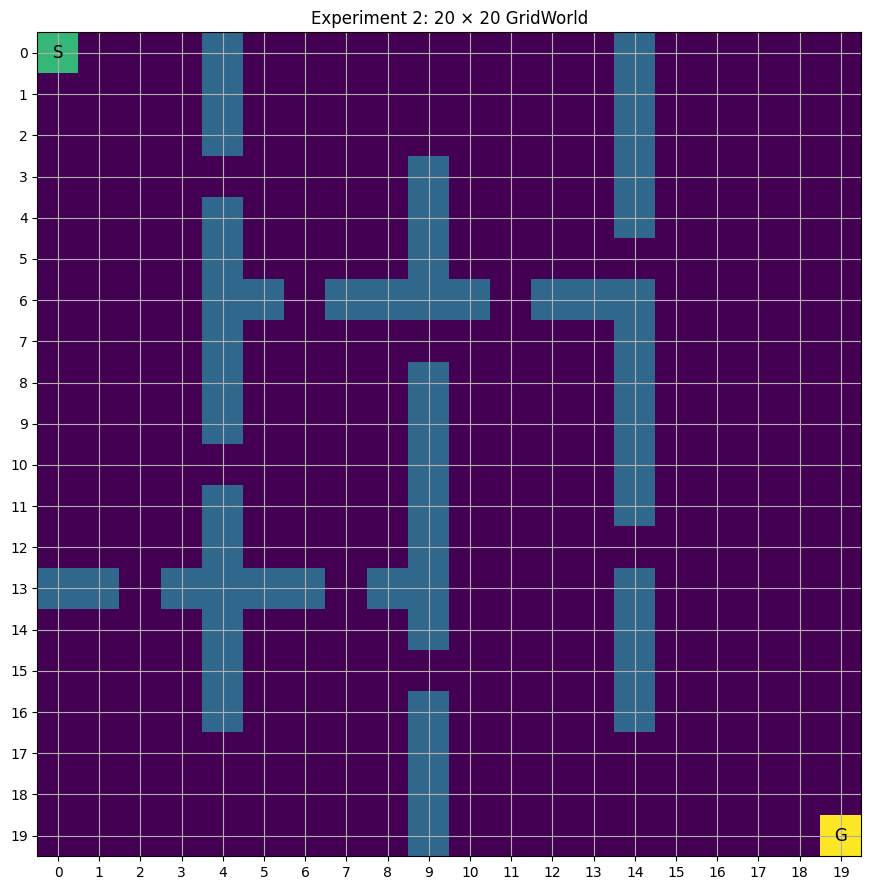



EXPERIMENT 2 COMPLETED SUCCESSFULLY

Generated files:
1. experiment2_success_rate.png
2. experiment2_reward.png
3. experiment2_steps.png
4. experiment2_adaptive_lambda.png
5. experiment2_final_success.png
6. experiment2_convergence.png
7. experiment2_environment.png
8. experiment2_summary.csv

FINAL TABLE:

           Method  Final Success Rate (%)  Success SD  Final Average Reward  Average Steps to Goal  Episodes to 90% Success
Sparse Q-Learning                  100.00        0.00                 1.000                  41.30                   385.40
       Fixed PBRS                   33.25       46.17                 0.332                 168.17                  2022.86
    Adaptive PBRS                   40.12       50.16                 0.401                 127.50                   772.00


In [ ]:
# ============================================================
# EXPERIMENT 2
# Performance-Adaptive Potential-Based Reward Shaping
# for Q-Learning in a Sparse-Reward 20x20 GridWorld

# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. ENVIRONMENT SETTINGS
# ============================================================

GRID = 20

START = (0, 0)
GOAL = (19, 19)

# ------------------------------------------------------------
# Obstacles
# These form several walls with gaps.
# A valid path from START to GOAL remains available.
# ------------------------------------------------------------

OBSTACLES = set()

# Vertical wall 1
for r in range(0, 17):
    if r not in [3, 10]:
        OBSTACLES.add((r, 4))

# Vertical wall 2
for r in range(3, 20):
    if r not in [7, 15]:
        OBSTACLES.add((r, 9))

# Vertical wall 3
for r in range(0, 17):
    if r not in [5, 12]:
        OBSTACLES.add((r, 14))

# Horizontal wall 1
for c in range(4, 15):
    if c not in [6, 11]:
        OBSTACLES.add((6, c))

# Horizontal wall 2
for c in range(0, 10):
    if c not in [2, 7]:
        OBSTACLES.add((13, c))

# Make sure start and goal are never obstacles
OBSTACLES.discard(START)
OBSTACLES.discard(GOAL)


# ============================================================
# 2. ACTION SPACE
# ============================================================

# 0 = Up
# 1 = Down
# 2 = Left
# 3 = Right

ACTIONS = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1)
]


# ============================================================
# 3. Q-LEARNING PARAMETERS
# ============================================================

N_EPISODES = 3000

N_SEEDS = 20

MAX_STEPS = 600

ALPHA = 0.10

GAMMA = 0.99

EPS_START = 1.0

EPS_MIN = 0.05

EPS_DECAY = 0.997


# ============================================================
# 4. REWARD-SHAPING PARAMETERS
# ============================================================

# Maximum shaping strength
LAMBDA0 = 1.0

# Number of recent episodes used to calculate performance
SUCCESS_WINDOW = 50


# ============================================================
# 5. POTENTIAL FUNCTION
# ============================================================

def phi(state):

    """
    Potential function.

    Negative normalized Manhattan distance to goal.

    Normalization keeps shaping rewards reasonably small
    relative to the +1 goal reward.
    """

    distance = (
        abs(state[0] - GOAL[0])
        +
        abs(state[1] - GOAL[1])
    )

    max_distance = 2 * (GRID - 1)

    return -distance / max_distance


# ============================================================
# 6. GRIDWORLD ENVIRONMENT
# ============================================================

def environment_step(state, action):

    dr, dc = ACTIONS[action]

    new_row = state[0] + dr
    new_col = state[1] + dc


    # --------------------------------------------------------
    # Boundary
    #
    # IMPORTANT:
    # No negative reward.
    # Agent simply remains in same state.
    # --------------------------------------------------------

    if (
        new_row < 0
        or new_row >= GRID
        or new_col < 0
        or new_col >= GRID
    ):

        return state, 0.0, False


    new_state = (
        new_row,
        new_col
    )


    # --------------------------------------------------------
    # Obstacle
    #
    # Again reward = 0.
    # This keeps environmental reward truly sparse.
    # --------------------------------------------------------

    if new_state in OBSTACLES:

        return state, 0.0, False


    # --------------------------------------------------------
    # Goal
    # --------------------------------------------------------

    if new_state == GOAL:

        return new_state, 1.0, True


    # --------------------------------------------------------
    # All normal states
    # --------------------------------------------------------

    return new_state, 0.0, False


# ============================================================
# 7. TRAINING FUNCTION
# ============================================================

def train(method, seed):

    rng = np.random.default_rng(seed)

    # Q table
    Q = np.zeros(
        (GRID, GRID, 4),
        dtype=np.float64
    )

    episode_rewards = []

    episode_success = []

    episode_steps = []

    lambda_history = []

    epsilon = EPS_START


    # ========================================================
    # EPISODE LOOP
    # ========================================================

    for episode in range(N_EPISODES):

        state = START

        total_environment_reward = 0.0

        success = 0

        steps_used = np.nan


        # ====================================================
        # CALCULATE SHAPING WEIGHT
        # ====================================================

        if method == "Sparse Q-Learning":

            lambda_value = 0.0


        elif method == "Fixed PBRS":

            lambda_value = LAMBDA0


        elif method == "Adaptive PBRS":

            # ------------------------------------------------
            # Performance-adaptive shaping
            #
            # lambda = lambda0 * (1 - recent success rate)
            #
            # Low success -> stronger shaping
            # High success -> weaker shaping
            # ------------------------------------------------

            if len(episode_success) == 0:

                recent_success = 0.0

            else:

                start_index = max(
                    0,
                    len(episode_success)
                    - SUCCESS_WINDOW
                )

                recent_success = np.mean(
                    episode_success[start_index:]
                )


            lambda_value = (
                LAMBDA0
                *
                (1.0 - recent_success)
            )


        lambda_history.append(
            lambda_value
        )


        # ====================================================
        # STEP LOOP
        # ====================================================

        for step_number in range(MAX_STEPS):


            # =================================================
            # EPSILON-GREEDY POLICY
            # =================================================

            if rng.random() < epsilon:

                action = rng.integers(4)

            else:

                q_values = Q[
                    state[0],
                    state[1]
                ]

                best_actions = np.flatnonzero(
                    q_values
                    ==
                    q_values.max()
                )

                action = rng.choice(
                    best_actions
                )


            # =================================================
            # ENVIRONMENT TRANSITION
            # =================================================

            next_state, reward, done = environment_step(
                state,
                action
            )


            total_environment_reward += reward


            # =================================================
            # REWARD CALCULATION
            # =================================================

            if method == "Sparse Q-Learning":

                learning_reward = reward


            else:

                # Potential-based reward shaping
                #
                # F(s,s') =
                # gamma * Phi(s') - Phi(s)

                shaping_reward = (
                    GAMMA * phi(next_state)
                    -
                    phi(state)
                )


                learning_reward = (
                    reward
                    +
                    lambda_value
                    *
                    shaping_reward
                )


            # =================================================
            # Q-LEARNING TARGET
            # =================================================

            if done:

                target = learning_reward

            else:

                target = (
                    learning_reward
                    +
                    GAMMA
                    *
                    np.max(
                        Q[
                            next_state[0],
                            next_state[1]
                        ]
                    )
                )


            # =================================================
            # Q-TABLE UPDATE
            # =================================================

            old_q = Q[
                state[0],
                state[1],
                action
            ]


            Q[
                state[0],
                state[1],
                action
            ] = (
                old_q
                +
                ALPHA
                *
                (
                    target
                    -
                    old_q
                )
            )


            state = next_state


            # =================================================
            # GOAL CHECK
            # =================================================

            if done:

                success = 1

                steps_used = (
                    step_number + 1
                )

                break


        # ====================================================
        # SAVE EPISODE DATA
        # ====================================================

        episode_rewards.append(
            total_environment_reward
        )

        episode_success.append(
            success
        )

        episode_steps.append(
            steps_used
        )


        # ====================================================
        # EPSILON DECAY
        # ====================================================

        epsilon = max(
            EPS_MIN,
            epsilon * EPS_DECAY
        )


    return {

        "reward":
            np.array(
                episode_rewards,
                dtype=float
            ),

        "success":
            np.array(
                episode_success,
                dtype=float
            ),

        "steps":
            np.array(
                episode_steps,
                dtype=float
            ),

        "lambda":
            np.array(
                lambda_history,
                dtype=float
            )
    }


# ============================================================
# 8. METHODS
# ============================================================

methods = [

    "Sparse Q-Learning",

    "Fixed PBRS",

    "Adaptive PBRS"

]


# ============================================================
# 9. RUN EXPERIMENT
# ============================================================

all_results = {}


print("=" * 70)

print(
    "EXPERIMENT 2: HARD SPARSE-REWARD GRIDWORLD"
)

print("=" * 70)


for method in methods:

    print(
        "\nTraining:",
        method
    )

    runs = []


    for seed in range(N_SEEDS):

        print(
            f"Seed {seed + 1}/{N_SEEDS}",
            end="\r"
        )

        result = train(
            method,
            seed
        )

        runs.append(
            result
        )


    all_results[method] = {

        "reward":
            np.vstack(
                [
                    run["reward"]
                    for run in runs
                ]
            ),

        "success":
            np.vstack(
                [
                    run["success"]
                    for run in runs
                ]
            ),

        "steps":
            np.vstack(
                [
                    run["steps"]
                    for run in runs
                ]
            ),

        "lambda":
            np.vstack(
                [
                    run["lambda"]
                    for run in runs
                ]
            )
    }


    print(
        method,
        "completed.          "
    )


# ============================================================
# 10. RESULT SUMMARY
# ============================================================

rows = []


for method in methods:

    data = all_results[method]


    # Final 200 episodes
    final_success_seed = (

        np.mean(
            data["success"][:, -200:],
            axis=1
        )

        * 100
    )


    final_reward_seed = np.mean(

        data["reward"][:, -200:],

        axis=1
    )


    # Average successful steps
    step_values = []

    for seed in range(N_SEEDS):

        successful_steps = (

            data["steps"][
                seed,
                -200:
            ]
        )

        successful_steps = successful_steps[
            ~np.isnan(successful_steps)
        ]


        if len(successful_steps) > 0:

            step_values.append(
                np.mean(
                    successful_steps
                )
            )

        else:

            step_values.append(
                np.nan
            )


    step_values = np.array(
        step_values
    )


    # --------------------------------------------------------
    # Episodes required to reach 90% rolling success
    # --------------------------------------------------------

    convergence_values = []


    for seed in range(N_SEEDS):

        success_array = (
            data["success"][seed]
        )

        rolling = (
            pd.Series(success_array)
            .rolling(
                SUCCESS_WINDOW
            )
            .mean()
        )


        reached = np.where(
            rolling.values >= 0.90
        )[0]


        if len(reached) > 0:

            convergence_values.append(
                reached[0] + 1
            )

        else:

            convergence_values.append(
                np.nan
            )


    convergence_values = np.array(
        convergence_values,
        dtype=float
    )


    rows.append({

        "Method":
            method,

        "Final Success Rate (%)":
            round(
                np.mean(
                    final_success_seed
                ),
                2
            ),

        "Success SD":
            round(
                np.std(
                    final_success_seed,
                    ddof=1
                ),
                2
            ),

        "Final Average Reward":
            round(
                np.mean(
                    final_reward_seed
                ),
                3
            ),

        "Average Steps to Goal":
            round(
                np.nanmean(
                    step_values
                ),
                2
            ),

        "Episodes to 90% Success":
            round(
                np.nanmean(
                    convergence_values
                ),
                2
            )
    })


summary = pd.DataFrame(
    rows
)


# ============================================================
# 11. PRINT RESULTS
# ============================================================

print("\n")

print("=" * 80)

print(
    "FINAL RESULTS - EXPERIMENT 2"
)

print("=" * 80)


display(
    summary
)


# ============================================================
# 12. MOVING AVERAGE FUNCTION
# ============================================================

def moving_average(
    data,
    window=100
):

    return np.convolve(

        data,

        np.ones(window)
        /
        window,

        mode="valid"
    )


WINDOW = 100


x = np.arange(

    WINDOW,

    N_EPISODES + 1

)


# ============================================================
# 13. GRAPH 1
# SUCCESS RATE
# ============================================================

plt.figure(
    figsize=(10, 6)
)


for method in methods:

    mean_success = (

        np.mean(

            all_results[method][
                "success"
            ],

            axis=0

        )

        * 100
    )


    smooth_success = moving_average(

        mean_success,

        WINDOW

    )


    plt.plot(

        x,

        smooth_success,

        label=method,

        linewidth=2

    )


plt.xlabel(
    "Episode"
)

plt.ylabel(
    "Success Rate (%)"
)

plt.title(
    "Experiment 2: Episode vs Success Rate"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()


plt.savefig(

    "experiment2_success_rate.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 14. GRAPH 2
# EPISODE VS ENVIRONMENTAL REWARD
# ============================================================

plt.figure(
    figsize=(10, 6)
)


for method in methods:

    mean_reward = np.mean(

        all_results[method][
            "reward"
        ],

        axis=0

    )


    smooth_reward = moving_average(

        mean_reward,

        WINDOW

    )


    plt.plot(

        x,

        smooth_reward,

        label=method,

        linewidth=2

    )


plt.xlabel(
    "Episode"
)

plt.ylabel(
    "Average Environmental Reward"
)

plt.title(
    "Experiment 2: Episode vs Reward"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()


plt.savefig(

    "experiment2_reward.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 15. GRAPH 3
# STEPS TO GOAL
# ============================================================

plt.figure(
    figsize=(10, 6)
)


for method in methods:

    steps_matrix = (
        all_results[method]["steps"]
    )

    mean_steps = []


    for episode in range(
        N_EPISODES
    ):

        values = (
            steps_matrix[:, episode]
        )

        values = values[
            ~np.isnan(values)
        ]


        if len(values) > 0:

            mean_steps.append(
                np.mean(values)
            )

        else:

            mean_steps.append(
                np.nan
            )


    mean_steps = np.array(
        mean_steps
    )


    # Fill gaps for visualization
    mean_steps = (

        pd.Series(mean_steps)

        .interpolate(
            limit_direction="both"
        )

        .to_numpy()

    )


    smooth_steps = moving_average(

        mean_steps,

        WINDOW

    )


    plt.plot(

        x,

        smooth_steps,

        label=method,

        linewidth=2

    )


plt.xlabel(
    "Episode"
)

plt.ylabel(
    "Average Steps to Goal"
)

plt.title(
    "Experiment 2: Episode vs Steps to Goal"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()


plt.savefig(

    "experiment2_steps.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 16. GRAPH 4
# ADAPTIVE LAMBDA
# ============================================================

adaptive_lambda = np.mean(

    all_results[
        "Adaptive PBRS"
    ]["lambda"],

    axis=0

)


smooth_lambda = moving_average(

    adaptive_lambda,

    WINDOW

)


plt.figure(
    figsize=(10, 6)
)


plt.plot(

    x,

    smooth_lambda,

    linewidth=2

)


plt.xlabel(
    "Episode"
)

plt.ylabel(
    "Adaptive Shaping Weight (Lambda)"
)

plt.title(
    "Adaptive PBRS: Shaping Weight During Training"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()


plt.savefig(

    "experiment2_adaptive_lambda.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 17. FINAL SUCCESS BAR GRAPH
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.bar(

    summary["Method"],

    summary[
        "Final Success Rate (%)"
    ]

)


plt.ylabel(
    "Final Success Rate (%)"
)

plt.title(
    "Experiment 2: Final Success Rate Comparison"
)

plt.ylim(
    0,
    105
)

plt.xticks(
    rotation=10
)

plt.tight_layout()


plt.savefig(

    "experiment2_final_success.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 18. CONVERGENCE BAR GRAPH
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.bar(

    summary["Method"],

    summary[
        "Episodes to 90% Success"
    ]

)


plt.ylabel(
    "Episodes"
)

plt.title(
    "Episodes Required to Reach 90% Success"
)

plt.xticks(
    rotation=10
)

plt.tight_layout()


plt.savefig(

    "experiment2_convergence.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 19. DISPLAY 20x20 GRIDWORLD
# ============================================================

grid_visual = np.zeros(
    (GRID, GRID)
)


for obstacle in OBSTACLES:

    grid_visual[
        obstacle[0],
        obstacle[1]
    ] = 1


grid_visual[
    START[0],
    START[1]
] = 2


grid_visual[
    GOAL[0],
    GOAL[1]
] = 3


plt.figure(
    figsize=(9, 9)
)


plt.imshow(
    grid_visual
)


plt.title(
    "Experiment 2: 20 × 20 GridWorld"
)


plt.xticks(
    range(GRID)
)

plt.yticks(
    range(GRID)
)

plt.grid()


# Labels
for i in range(GRID):

    for j in range(GRID):

        if (i, j) == START:

            plt.text(
                j,
                i,
                "S",
                ha="center",
                va="center",
                fontsize=12
            )


        elif (i, j) == GOAL:

            plt.text(
                j,
                i,
                "G",
                ha="center",
                va="center",
                fontsize=12
            )


plt.tight_layout()


plt.savefig(

    "experiment2_environment.png",

    dpi=300,

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 20. SAVE RESULTS
# ============================================================

summary.to_csv(

    "experiment2_summary.csv",

    index=False

)


# ============================================================
# 21. PRINT FINAL OUTPUT
# ============================================================

print("\n")

print("=" * 80)

print(
    "EXPERIMENT 2 COMPLETED SUCCESSFULLY"
)

print("=" * 80)


print("\nGenerated files:")

print(
    "1. experiment2_success_rate.png"
)

print(
    "2. experiment2_reward.png"
)

print(
    "3. experiment2_steps.png"
)

print(
    "4. experiment2_adaptive_lambda.png"
)

print(
    "5. experiment2_final_success.png"
)

print(
    "6. experiment2_convergence.png"
)

print(
    "7. experiment2_environment.png"
)

print(
    "8. experiment2_summary.csv"
)


print("\nFINAL TABLE:\n")

print(
    summary.to_string(
        index=False
    )
)

Shortest valid START -> GOAL distance: 38
Reachable states: 343

EXPERIMENT 3 STARTED

Training: Sparse Q-Learning
  Seed 1/5 completed in 19.3 sec
  Seed 2/5 completed in 14.4 sec
  Seed 3/5 completed in 14.8 sec
  Seed 4/5 completed in 15.3 sec
  Seed 5/5 completed in 14.8 sec
Sparse Q-Learning finished in 78.6 seconds.

Training: Fixed PBRS Manhattan
  Seed 1/5 completed in 16.4 sec
  Seed 2/5 completed in 15.7 sec
  Seed 3/5 completed in 15.8 sec
  Seed 4/5 completed in 16.0 sec
  Seed 5/5 completed in 16.8 sec
Fixed PBRS Manhattan finished in 80.6 seconds.

Training: Adaptive PBRS Manhattan
  Seed 1/5 completed in 15.7 sec
  Seed 2/5 completed in 15.9 sec
  Seed 3/5 completed in 15.9 sec
  Seed 4/5 completed in 16.2 sec
  Seed 5/5 completed in 17.1 sec
Adaptive PBRS Manhattan finished in 80.8 seconds.

Training: Adaptive PBRS Obstacle-Aware
  Seed 1/5 completed in 2.9 sec
  Seed 2/5 completed in 7.6 sec
  Seed 3/5 completed in 4.1 sec
  Seed 4/5 completed in 3.3 sec
  Seed 5/5 com

/tmp/ipykernel_3985/3871961764.py:735: RuntimeWarning: Mean of empty slice
  np.nanmean(


,Method,Final Success Rate (%),Success SD,Average Steps to Goal,Seeds Reaching 90%,Episodes to 90% Success
0,Sparse Q-Learning,1.0,0.94,252.18,0,NaN
1,Fixed PBRS Manhattan,0.0,0.00,NaN,0,NaN
2,Adaptive PBRS Manhattan,0.1,0.22,77.00,0,NaN
3,Adaptive PBRS Obstacle-Aware,100.0,0.00,40.29,5,143.8


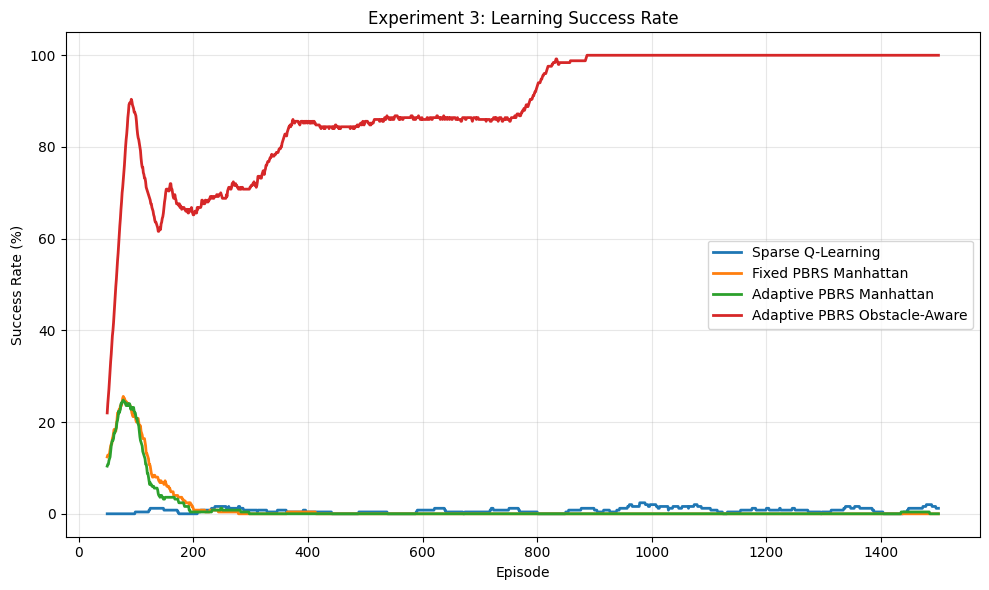

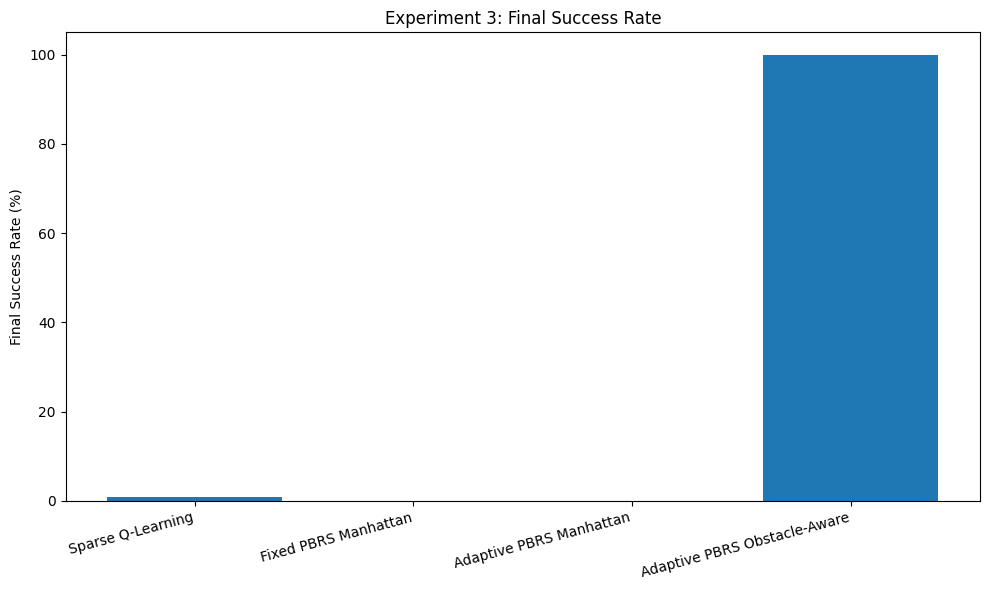

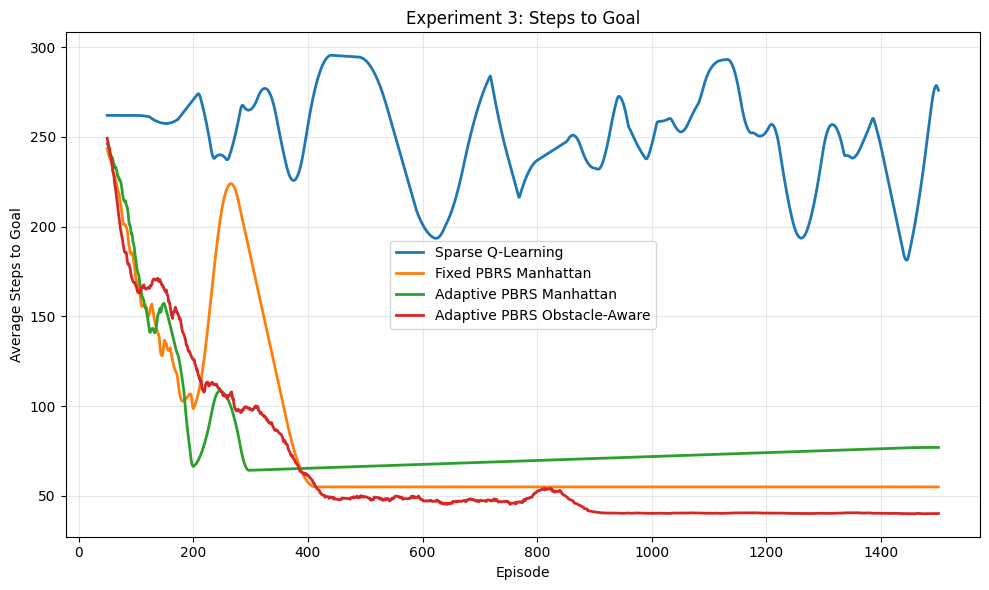

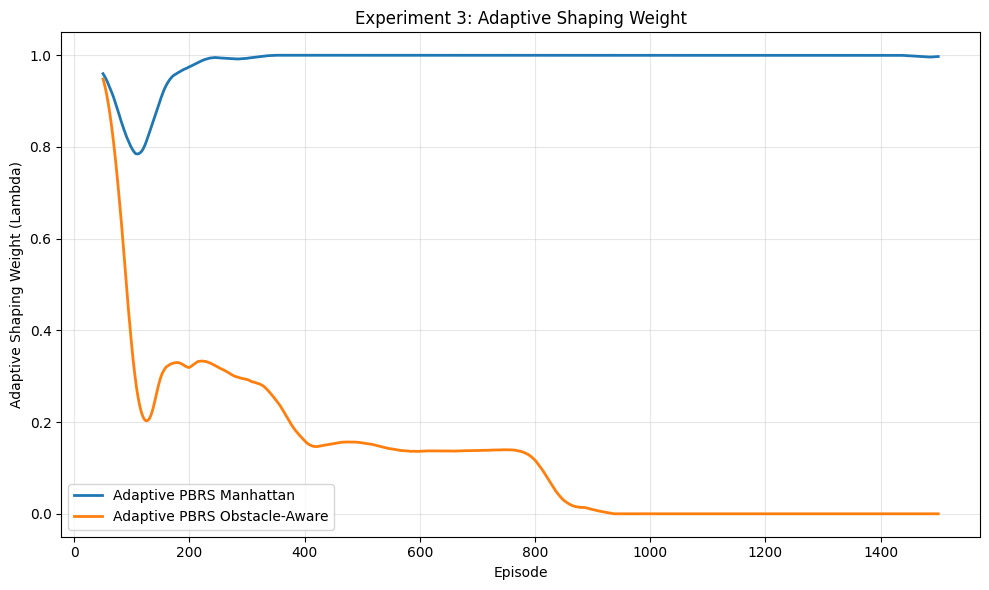

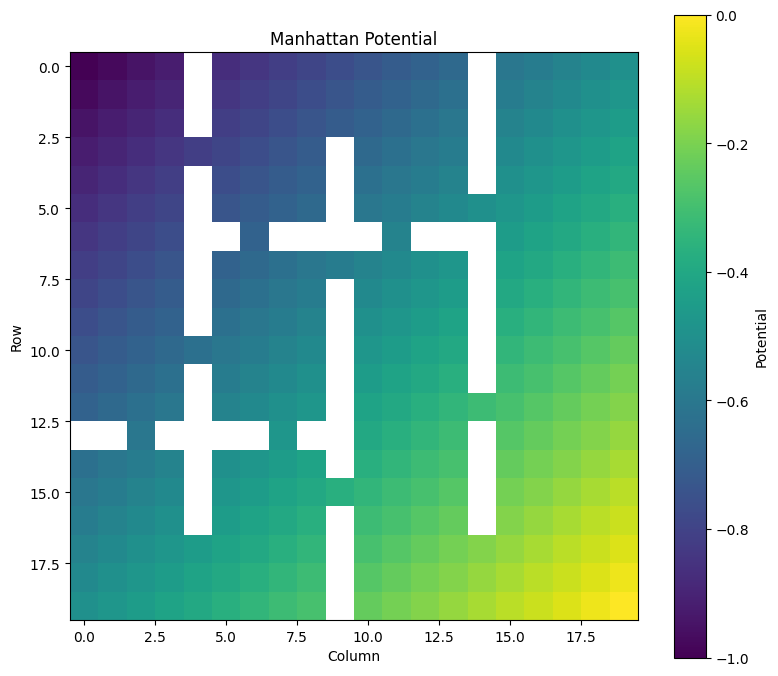

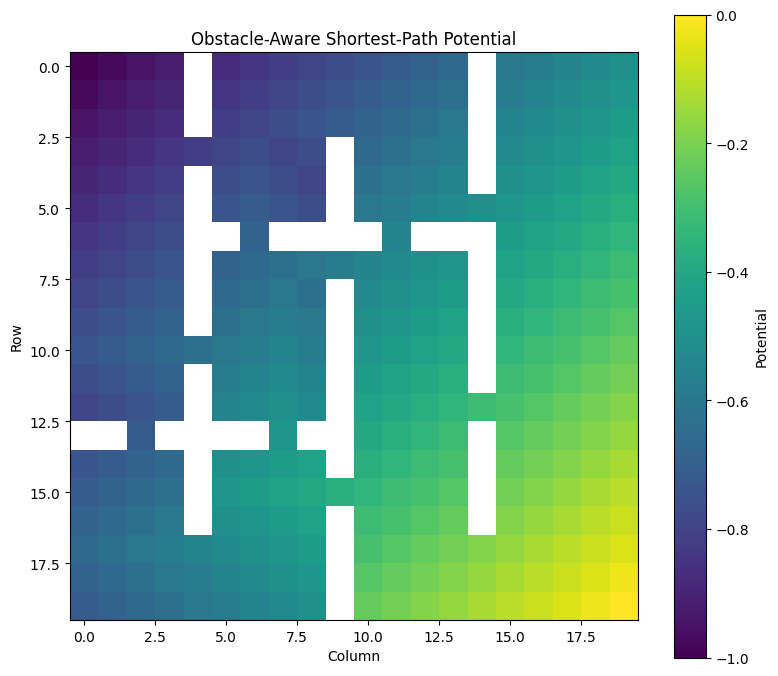

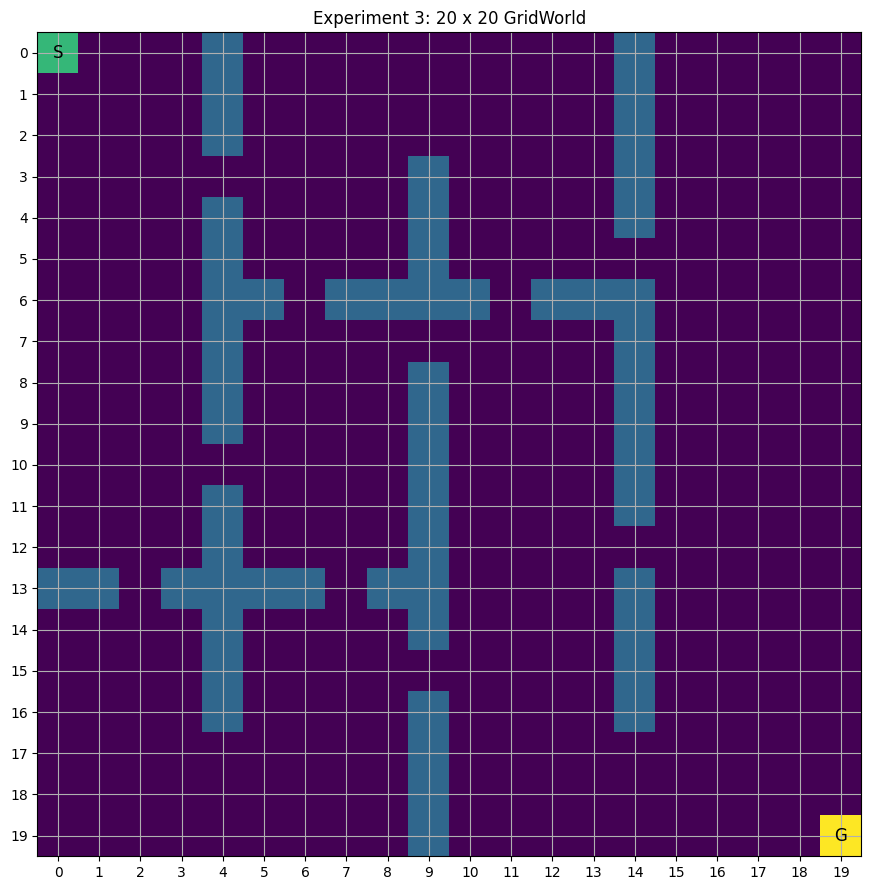


EXPERIMENT 3 COMPLETED

Total execution time: 4.49 minutes

FINAL TABLE:

                      Method  Final Success Rate (%)  Success SD  Average Steps to Goal  Seeds Reaching 90%  Episodes to 90% Success
           Sparse Q-Learning                     1.0        0.94                 252.18                   0                      NaN
        Fixed PBRS Manhattan                     0.0        0.00                    NaN                   0                      NaN
     Adaptive PBRS Manhattan                     0.1        0.22                  77.00                   0                      NaN
Adaptive PBRS Obstacle-Aware                   100.0        0.00                  40.29                   5                    143.8

Generated files:
1. experiment3_summary.csv
2. experiment3_success.png
3. experiment3_final_success.png
4. experiment3_steps.png
5. experiment3_lambda.png
6. experiment3_manhattan_potential.png
7. experiment3_obstacle_potential.png
8. experiment3_environment.

In [ ]:
# ================================================================
# EXPERIMENT 3
# Obstacle-Aware Performance-Adaptive Reward Shaping
# in Sparse-Reward GridWorld
#
# Google Colab Compatible
# Paste EVERYTHING into ONE cell and run.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
import time


# ================================================================
# 1. ENVIRONMENT
# ================================================================

GRID = 20

START = (0, 0)
GOAL = (19, 19)

OBSTACLES = set()

# Vertical wall 1
for r in range(0, 17):
    if r not in [3, 10]:
        OBSTACLES.add((r, 4))

# Vertical wall 2
for r in range(3, 20):
    if r not in [7, 15]:
        OBSTACLES.add((r, 9))

# Vertical wall 3
for r in range(0, 17):
    if r not in [5, 12]:
        OBSTACLES.add((r, 14))

# Horizontal wall 1
for c in range(4, 15):
    if c not in [6, 11]:
        OBSTACLES.add((6, c))

# Horizontal wall 2
for c in range(0, 10):
    if c not in [2, 7]:
        OBSTACLES.add((13, c))

OBSTACLES.discard(START)
OBSTACLES.discard(GOAL)


# ================================================================
# 2. ACTIONS
# ================================================================

# 0 = Up
# 1 = Down
# 2 = Left
# 3 = Right

ACTIONS = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1)
]


# ================================================================
# 3. PARAMETERS
# ================================================================

# Faster pilot experiment
N_EPISODES = 1500
N_SEEDS = 5
MAX_STEPS = 300

ALPHA = 0.10
GAMMA = 0.99

EPS_START = 1.0
EPS_MIN = 0.05
EPS_DECAY = 0.995

LAMBDA0 = 1.0

SUCCESS_WINDOW = 50

# Moving average for plots
PLOT_WINDOW = 50


# ================================================================
# 4. ENVIRONMENT STEP
# ================================================================

def environment_step(state, action):

    dr, dc = ACTIONS[action]

    nr = state[0] + dr
    nc = state[1] + dc

    # Boundary
    if nr < 0 or nr >= GRID or nc < 0 or nc >= GRID:
        return state, 0.0, False

    next_state = (nr, nc)

    # Obstacle
    if next_state in OBSTACLES:
        return state, 0.0, False

    # Goal
    if next_state == GOAL:
        return next_state, 1.0, True

    # Sparse reward
    return next_state, 0.0, False


# ================================================================
# 5. MANHATTAN POTENTIAL
# ================================================================

def manhattan_phi(state):

    distance = (
        abs(state[0] - GOAL[0])
        +
        abs(state[1] - GOAL[1])
    )

    max_distance = 2 * (GRID - 1)

    return -distance / max_distance


# ================================================================
# 6. OBSTACLE-AWARE SHORTEST-PATH DISTANCE
#
# We run BFS backwards from the goal.
# This gives actual traversable shortest distance from every
# reachable cell to the goal.
# ================================================================

def compute_shortest_distances():

    distances = {}

    queue = deque()

    queue.append(GOAL)

    distances[GOAL] = 0

    while queue:

        current = queue.popleft()

        current_distance = distances[current]

        for dr, dc in ACTIONS:

            nr = current[0] + dr
            nc = current[1] + dc

            next_state = (nr, nc)

            if nr < 0 or nr >= GRID:
                continue

            if nc < 0 or nc >= GRID:
                continue

            if next_state in OBSTACLES:
                continue

            if next_state not in distances:

                distances[next_state] = (
                    current_distance + 1
                )

                queue.append(next_state)

    return distances


SHORTEST_DISTANCE = compute_shortest_distances()

if START not in SHORTEST_DISTANCE:
    raise ValueError(
        "ERROR: No valid path exists from START to GOAL."
    )

MAX_SHORTEST_DISTANCE = max(
    SHORTEST_DISTANCE.values()
)

print("Shortest valid START -> GOAL distance:",
      SHORTEST_DISTANCE[START])

print("Reachable states:",
      len(SHORTEST_DISTANCE))


# ================================================================
# 7. OBSTACLE-AWARE POTENTIAL
# ================================================================

def obstacle_phi(state):

    if state not in SHORTEST_DISTANCE:
        return -1.0

    distance = SHORTEST_DISTANCE[state]

    return -distance / MAX_SHORTEST_DISTANCE


# ================================================================
# 8. METHODS
# ================================================================

methods = [

    "Sparse Q-Learning",

    "Fixed PBRS Manhattan",

    "Adaptive PBRS Manhattan",

    "Adaptive PBRS Obstacle-Aware"

]


# ================================================================
# 9. TRAINING FUNCTION
# ================================================================

def train(method, seed):

    rng = np.random.default_rng(seed)

    Q = np.zeros(
        (GRID, GRID, 4),
        dtype=np.float64
    )

    rewards = np.zeros(N_EPISODES)
    successes = np.zeros(N_EPISODES)

    steps = np.full(
        N_EPISODES,
        np.nan
    )

    lambdas = np.zeros(N_EPISODES)

    epsilon = EPS_START


    for episode in range(N_EPISODES):

        state = START

        success = 0

        # --------------------------------------------------------
        # Calculate lambda
        # --------------------------------------------------------

        if method == "Sparse Q-Learning":

            lambda_value = 0.0

        elif method == "Fixed PBRS Manhattan":

            lambda_value = LAMBDA0

        else:

            # Recent performance
            if episode == 0:

                recent_success = 0.0

            else:

                begin = max(
                    0,
                    episode - SUCCESS_WINDOW
                )

                recent_success = np.mean(
                    successes[begin:episode]
                )

            # Performance-adaptive shaping
            lambda_value = (
                LAMBDA0
                *
                (1.0 - recent_success)
            )

        lambdas[episode] = lambda_value


        # --------------------------------------------------------
        # Run episode
        # --------------------------------------------------------

        for step_number in range(MAX_STEPS):

            # Epsilon greedy
            if rng.random() < epsilon:

                action = rng.integers(4)

            else:

                q_values = Q[
                    state[0],
                    state[1]
                ]

                best_actions = np.flatnonzero(
                    q_values == q_values.max()
                )

                action = rng.choice(
                    best_actions
                )


            next_state, env_reward, done = (
                environment_step(
                    state,
                    action
                )
            )


            # ----------------------------------------------------
            # Select reward
            # ----------------------------------------------------

            if method == "Sparse Q-Learning":

                learning_reward = env_reward


            elif (
                method == "Fixed PBRS Manhattan"
                or
                method == "Adaptive PBRS Manhattan"
            ):

                shaping = (
                    GAMMA
                    *
                    manhattan_phi(next_state)
                    -
                    manhattan_phi(state)
                )

                learning_reward = (
                    env_reward
                    +
                    lambda_value
                    *
                    shaping
                )


            elif method == "Adaptive PBRS Obstacle-Aware":

                shaping = (
                    GAMMA
                    *
                    obstacle_phi(next_state)
                    -
                    obstacle_phi(state)
                )

                learning_reward = (
                    env_reward
                    +
                    lambda_value
                    *
                    shaping
                )


            # ----------------------------------------------------
            # Q update
            # ----------------------------------------------------

            if done:

                target = learning_reward

            else:

                target = (
                    learning_reward
                    +
                    GAMMA
                    *
                    np.max(
                        Q[
                            next_state[0],
                            next_state[1]
                        ]
                    )
                )


            current_q = Q[
                state[0],
                state[1],
                action
            ]


            Q[
                state[0],
                state[1],
                action
            ] = (
                current_q
                +
                ALPHA
                *
                (
                    target
                    -
                    current_q
                )
            )


            state = next_state


            if done:

                success = 1

                rewards[episode] = 1.0

                successes[episode] = 1.0

                steps[episode] = (
                    step_number + 1
                )

                break


        if success == 0:

            rewards[episode] = 0.0

            successes[episode] = 0.0


        epsilon = max(
            EPS_MIN,
            epsilon * EPS_DECAY
        )


    return {

        "reward": rewards,

        "success": successes,

        "steps": steps,

        "lambda": lambdas
    }


# ================================================================
# 10. RUN EXPERIMENT
# ================================================================

all_results = {}

start_time = time.time()

print("\n" + "=" * 70)

print("EXPERIMENT 3 STARTED")

print("=" * 70)


for method in methods:

    method_start = time.time()

    print("\nTraining:", method)

    runs = []


    for seed in range(N_SEEDS):

        seed_start = time.time()

        result = train(
            method,
            seed
        )

        runs.append(result)

        elapsed_seed = (
            time.time()
            -
            seed_start
        )

        print(
            f"  Seed {seed + 1}/{N_SEEDS}"
            f" completed in "
            f"{elapsed_seed:.1f} sec"
        )


    all_results[method] = {

        "reward":
            np.vstack(
                [
                    run["reward"]
                    for run in runs
                ]
            ),

        "success":
            np.vstack(
                [
                    run["success"]
                    for run in runs
                ]
            ),

        "steps":
            np.vstack(
                [
                    run["steps"]
                    for run in runs
                ]
            ),

        "lambda":
            np.vstack(
                [
                    run["lambda"]
                    for run in runs
                ]
            )
    }


    print(
        method,
        "finished in",
        round(
            time.time()
            -
            method_start,
            1
        ),
        "seconds."
    )


# ================================================================
# 11. CALCULATE RESULTS
# ================================================================

rows = []


for method in methods:

    data = all_results[method]

    # ------------------------------------------------------------
    # Final 200 episode success
    # ------------------------------------------------------------

    final_success_seed = (

        np.mean(
            data["success"][:, -200:],
            axis=1
        )

        * 100
    )


    # ------------------------------------------------------------
    # Average steps in final 200 successful episodes
    # ------------------------------------------------------------

    average_steps_seed = []


    for seed in range(N_SEEDS):

        values = (
            data["steps"][
                seed,
                -200:
            ]
        )

        valid = values[
            ~np.isnan(values)
        ]


        if len(valid) > 0:

            average_steps_seed.append(
                np.mean(valid)
            )

        else:

            average_steps_seed.append(
                np.nan
            )


    average_steps_seed = np.array(
        average_steps_seed
    )


    # ------------------------------------------------------------
    # First episode where rolling success reaches >= 90%
    # ------------------------------------------------------------

    convergence_seed = []


    for seed in range(N_SEEDS):

        rolling = (

            pd.Series(
                data["success"][seed]
            )

            .rolling(
                SUCCESS_WINDOW
            )

            .mean()

        )


        reached = np.where(
            rolling.values >= 0.90
        )[0]


        if len(reached) > 0:

            convergence_seed.append(
                reached[0] + 1
            )

        else:

            convergence_seed.append(
                np.nan
            )


    convergence_seed = np.array(
        convergence_seed,
        dtype=float
    )


    # Number of seeds reaching criterion
    seeds_reaching_90 = np.sum(
        ~np.isnan(
            convergence_seed
        )
    )


    rows.append({

        "Method":
            method,

        "Final Success Rate (%)":
            round(
                np.mean(
                    final_success_seed
                ),
                2
            ),

        "Success SD":
            round(
                np.std(
                    final_success_seed,
                    ddof=1
                ),
                2
            ),

        "Average Steps to Goal":
            round(
                np.nanmean(
                    average_steps_seed
                ),
                2
            ),

        "Seeds Reaching 90%":
            int(
                seeds_reaching_90
            ),

        "Episodes to 90% Success":
            (
                round(
                    np.nanmean(
                        convergence_seed
                    ),
                    2
                )
                if seeds_reaching_90 > 0
                else np.nan
            )
    })


summary = pd.DataFrame(rows)


# ================================================================
# 12. DISPLAY FINAL TABLE
# ================================================================

print("\n" + "=" * 85)

print("EXPERIMENT 3 RESULTS")

print("=" * 85)

display(summary)


# ================================================================
# 13. MOVING AVERAGE
# ================================================================

def moving_average(data, window):

    return np.convolve(
        data,
        np.ones(window) / window,
        mode="valid"
    )


x = np.arange(
    PLOT_WINDOW,
    N_EPISODES + 1
)


# ================================================================
# 14. SUCCESS-RATE GRAPH
# ================================================================

plt.figure(figsize=(10, 6))


for method in methods:

    mean_success = (

        np.mean(
            all_results[method]["success"],
            axis=0
        )

        * 100
    )


    smooth = moving_average(
        mean_success,
        PLOT_WINDOW
    )


    plt.plot(
        x,
        smooth,
        label=method,
        linewidth=2
    )


plt.xlabel("Episode")

plt.ylabel("Success Rate (%)")

plt.title(
    "Experiment 3: Learning Success Rate"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "experiment3_success.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 15. FINAL SUCCESS BAR GRAPH
# ================================================================

plt.figure(figsize=(10, 6))

plt.bar(
    summary["Method"],
    summary["Final Success Rate (%)"]
)

plt.ylabel(
    "Final Success Rate (%)"
)

plt.title(
    "Experiment 3: Final Success Rate"
)

plt.ylim(0, 105)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "experiment3_final_success.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 16. STEPS-TO-GOAL GRAPH
# ================================================================

plt.figure(figsize=(10, 6))


for method in methods:

    steps_matrix = (
        all_results[method]["steps"]
    )

    mean_steps = []


    for episode in range(N_EPISODES):

        values = (
            steps_matrix[:, episode]
        )

        valid = values[
            ~np.isnan(values)
        ]


        if len(valid) > 0:

            mean_steps.append(
                np.mean(valid)
            )

        else:

            mean_steps.append(
                np.nan
            )


    mean_steps = np.array(
        mean_steps
    )


    # Interpolation is only for visualizing the curve.
    mean_steps = (

        pd.Series(mean_steps)

        .interpolate(
            limit_direction="both"
        )

        .to_numpy()
    )


    smooth = moving_average(
        mean_steps,
        PLOT_WINDOW
    )


    plt.plot(
        x,
        smooth,
        label=method,
        linewidth=2
    )


plt.xlabel("Episode")

plt.ylabel(
    "Average Steps to Goal"
)

plt.title(
    "Experiment 3: Steps to Goal"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "experiment3_steps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 17. ADAPTIVE LAMBDA COMPARISON
# ================================================================

plt.figure(figsize=(10, 6))


for method in [
    "Adaptive PBRS Manhattan",
    "Adaptive PBRS Obstacle-Aware"
]:

    mean_lambda = np.mean(
        all_results[method]["lambda"],
        axis=0
    )

    smooth_lambda = moving_average(
        mean_lambda,
        PLOT_WINDOW
    )

    plt.plot(
        x,
        smooth_lambda,
        label=method,
        linewidth=2
    )


plt.xlabel("Episode")

plt.ylabel(
    "Adaptive Shaping Weight (Lambda)"
)

plt.title(
    "Experiment 3: Adaptive Shaping Weight"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "experiment3_lambda.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 18. POTENTIAL COMPARISON HEATMAPS
# ================================================================

manhattan_map = np.full(
    (GRID, GRID),
    np.nan
)

obstacle_map = np.full(
    (GRID, GRID),
    np.nan
)


for r in range(GRID):

    for c in range(GRID):

        state = (r, c)

        if state not in OBSTACLES:

            manhattan_map[r, c] = (
                manhattan_phi(state)
            )

            obstacle_map[r, c] = (
                obstacle_phi(state)
            )


plt.figure(figsize=(8, 7))

plt.imshow(
    manhattan_map
)

plt.title(
    "Manhattan Potential"
)

plt.xlabel("Column")

plt.ylabel("Row")

plt.colorbar(
    label="Potential"
)

plt.tight_layout()

plt.savefig(
    "experiment3_manhattan_potential.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(8, 7))

plt.imshow(
    obstacle_map
)

plt.title(
    "Obstacle-Aware Shortest-Path Potential"
)

plt.xlabel("Column")

plt.ylabel("Row")

plt.colorbar(
    label="Potential"
)

plt.tight_layout()

plt.savefig(
    "experiment3_obstacle_potential.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 19. GRIDWORLD
# ================================================================

grid_visual = np.zeros(
    (GRID, GRID)
)


for obstacle in OBSTACLES:

    grid_visual[
        obstacle[0],
        obstacle[1]
    ] = 1


grid_visual[
    START[0],
    START[1]
] = 2


grid_visual[
    GOAL[0],
    GOAL[1]
] = 3


plt.figure(figsize=(9, 9))

plt.imshow(
    grid_visual
)

plt.title(
    "Experiment 3: 20 x 20 GridWorld"
)

plt.xticks(range(GRID))

plt.yticks(range(GRID))

plt.grid()


plt.text(
    START[1],
    START[0],
    "S",
    ha="center",
    va="center",
    fontsize=12
)

plt.text(
    GOAL[1],
    GOAL[0],
    "G",
    ha="center",
    va="center",
    fontsize=12
)

plt.tight_layout()

plt.savefig(
    "experiment3_environment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 20. SAVE CSV
# ================================================================

summary.to_csv(
    "experiment3_summary.csv",
    index=False
)


# ================================================================
# 21. FINAL OUTPUT
# ================================================================

total_time = (
    time.time()
    -
    start_time
)


print("\n" + "=" * 85)

print(
    "EXPERIMENT 3 COMPLETED"
)

print("=" * 85)


print(
    "\nTotal execution time:",
    round(
        total_time / 60,
        2
    ),
    "minutes"
)


print("\nFINAL TABLE:\n")

print(
    summary.to_string(
        index=False
    )
)


print("\nGenerated files:")

print("1. experiment3_summary.csv")
print("2. experiment3_success.png")
print("3. experiment3_final_success.png")
print("4. experiment3_steps.png")
print("5. experiment3_lambda.png")
print("6. experiment3_manhattan_potential.png")
print("7. experiment3_obstacle_potential.png")
print("8. experiment3_environment.png")

Environment check
-----------------
Grid: 20 x 20
Start: (0, 0)
Goal: (19, 19)
Obstacles: 57
Shortest valid path: 38 steps

EXPERIMENT 4 STARTED

Training: Sparse Q-Learning
 Seed 1/10 completed in 9.0 sec
 Seed 2/10 completed in 5.1 sec
 Seed 3/10 completed in 7.0 sec
 Seed 4/10 completed in 7.1 sec
 Seed 5/10 completed in 7.4 sec
 Seed 6/10 completed in 8.2 sec
 Seed 7/10 completed in 9.6 sec
 Seed 8/10 completed in 9.7 sec
 Seed 9/10 completed in 6.3 sec
 Seed 10/10 completed in 7.6 sec
Sparse Q-Learning completed in 77.0 seconds.

Training: Fixed PBRS Manhattan
 Seed 1/10 completed in 58.2 sec
 Seed 2/10 completed in 49.7 sec
 Seed 3/10 completed in 57.3 sec
 Seed 4/10 completed in 13.4 sec
 Seed 5/10 completed in 58.1 sec
 Seed 6/10 completed in 56.9 sec
 Seed 7/10 completed in 47.5 sec
 Seed 8/10 completed in 56.8 sec
 Seed 9/10 completed in 60.2 sec
 Seed 10/10 completed in 60.7 sec
Fixed PBRS Manhattan completed in 518.9 seconds.

Training: Adaptive PBRS Manhattan
 Seed 1/10 co

,Method,Final Success Rate (%),Success SD,Average Steps to Goal,First Successful Episode,Seeds Reaching 90%,Episodes to 90% Success
0,Sparse Q-Learning,100.00,0.0,41.48,21.1,10,378.00
1,Fixed PBRS Manhattan,35.75,46.9,207.84,14.0,4,2197.00
2,Adaptive PBRS Manhattan,30.15,48.2,202.02,14.0,3,832.67
3,Fixed PBRS Obstacle-Aware,100.00,0.0,40.25,11.9,10,82.40
4,Adaptive PBRS Obstacle-Aware,100.00,0.0,40.40,11.9,10,525.80


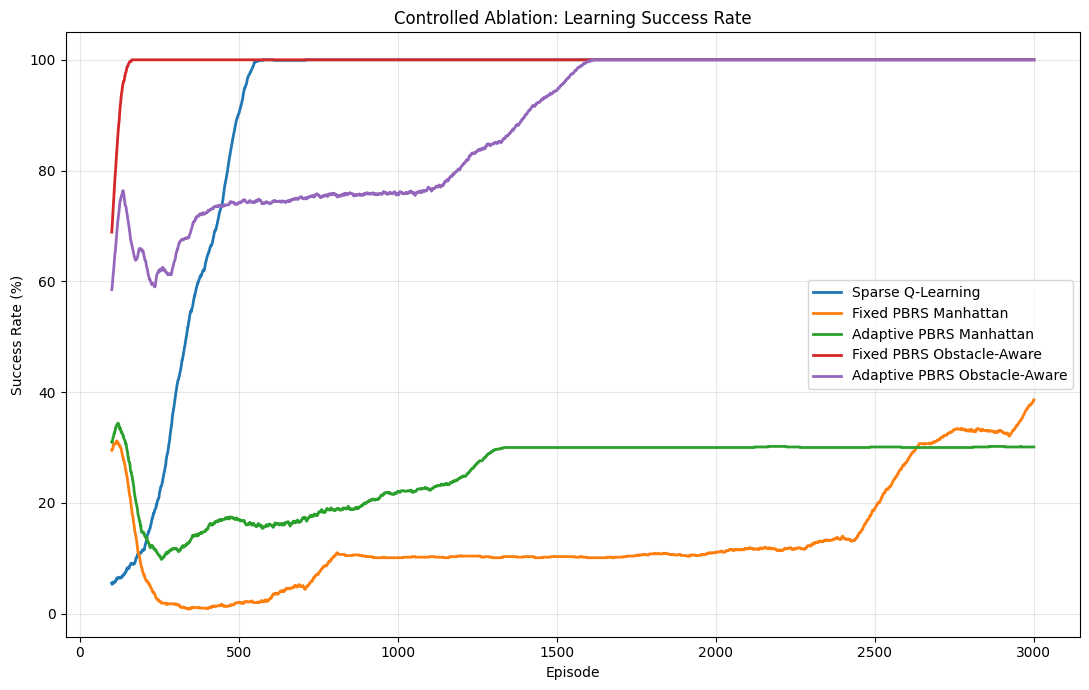

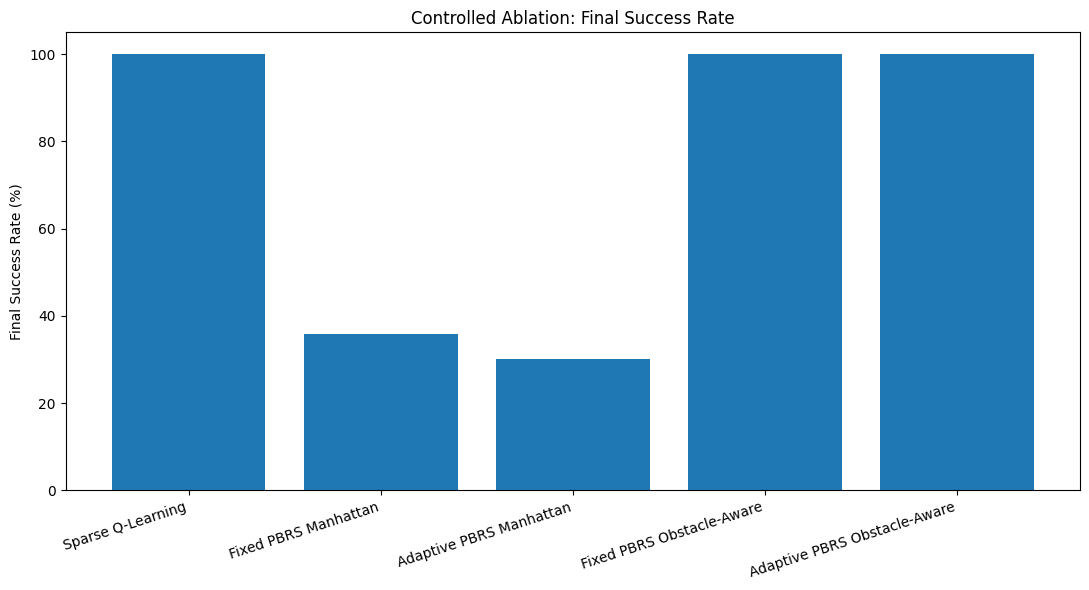

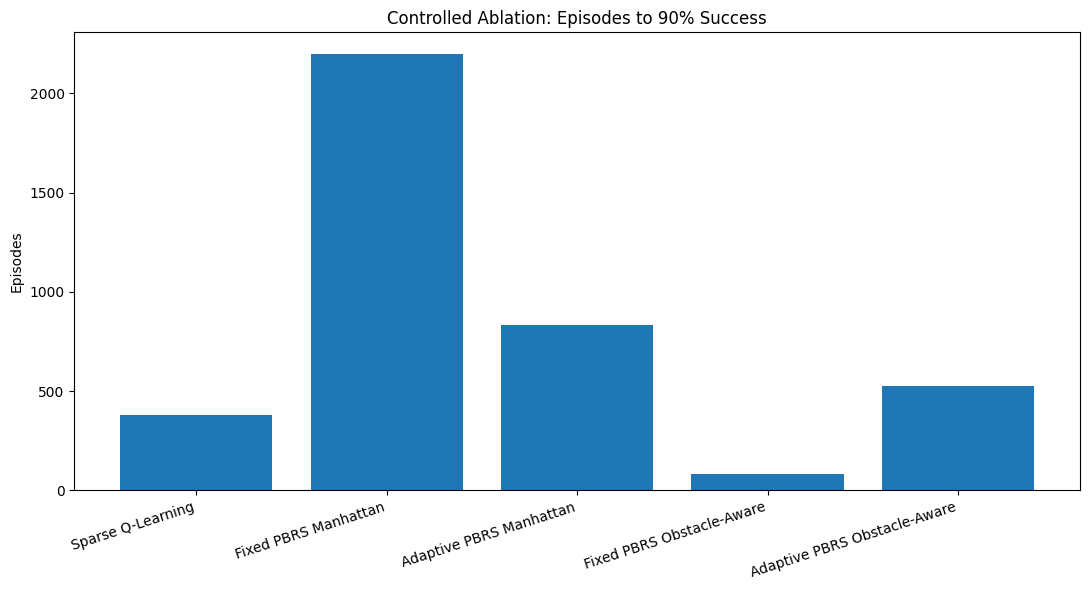

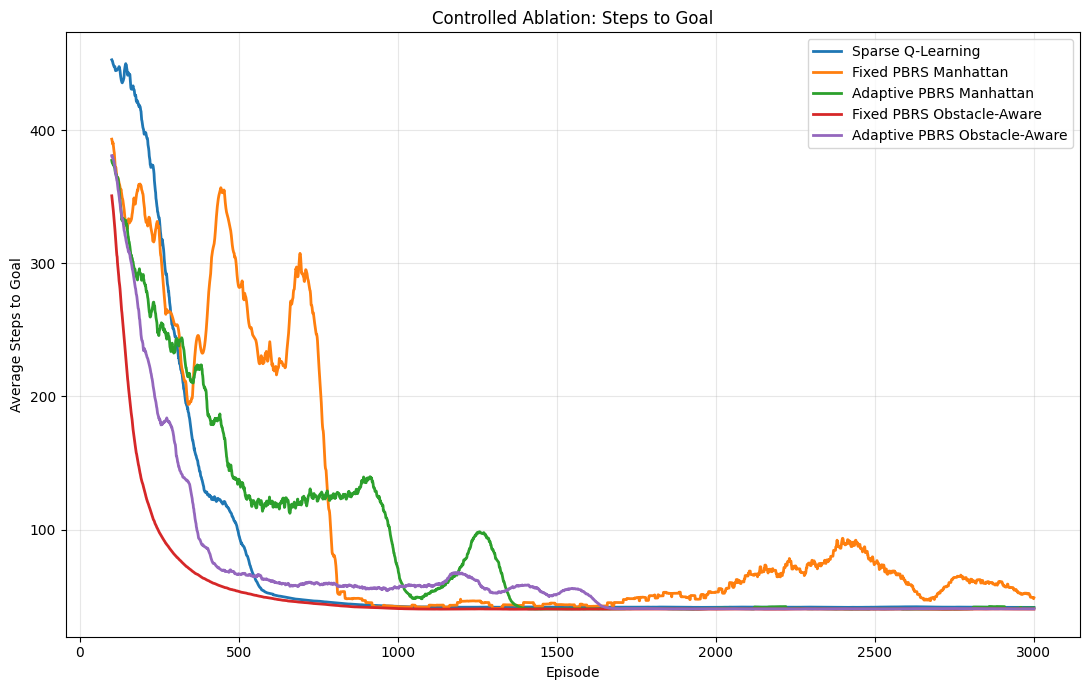

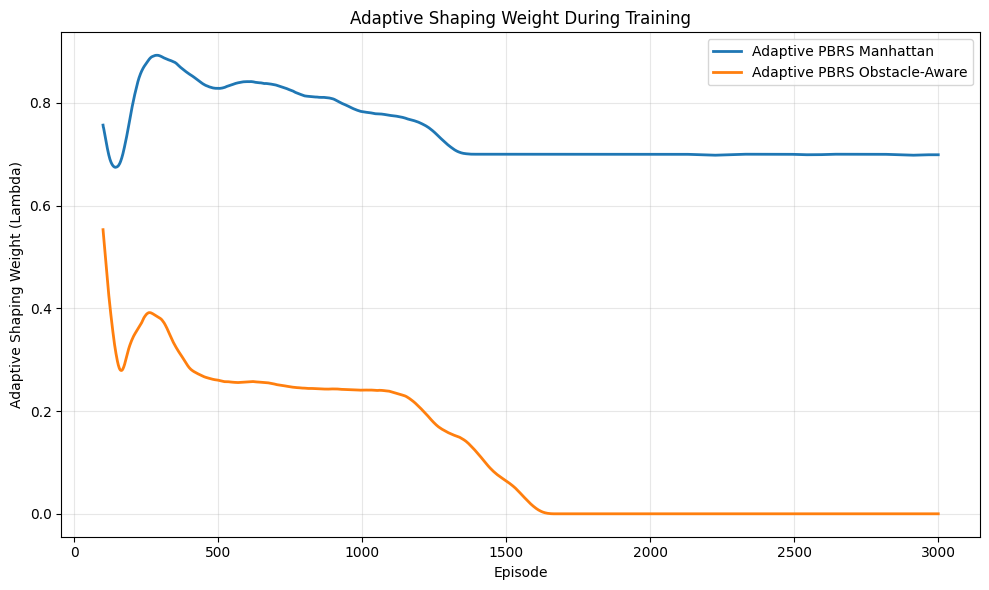

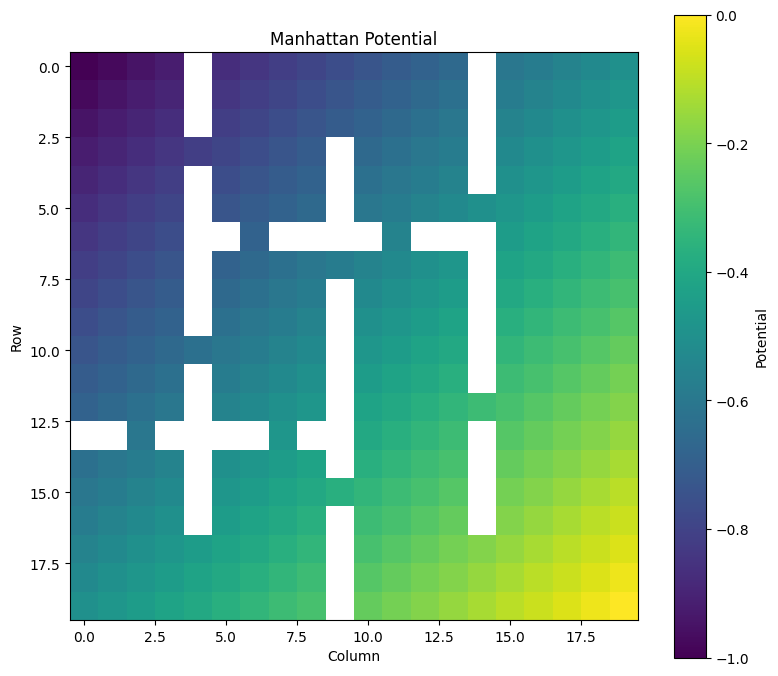

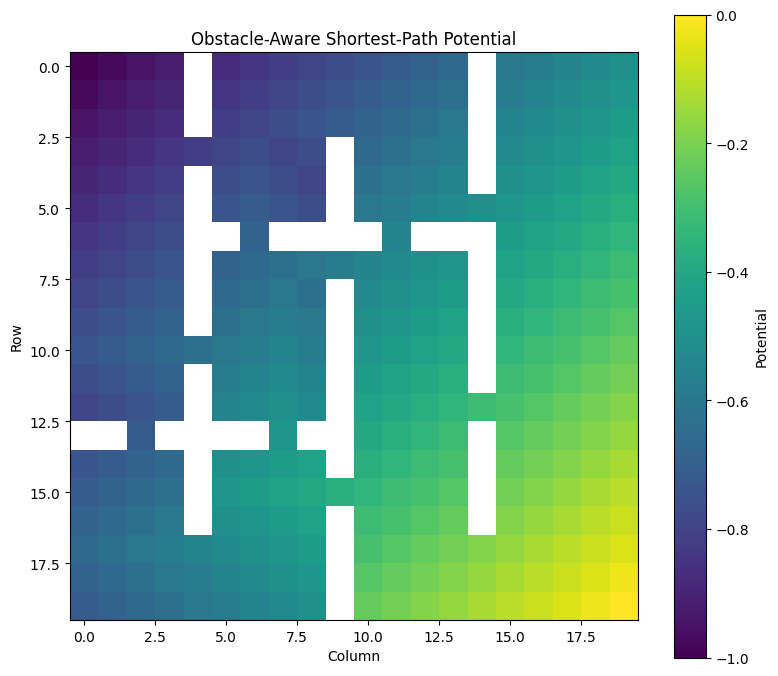


EXPERIMENT 4 COMPLETED

Total execution time: 20.5 minutes

FINAL TABLE:

                      Method  Final Success Rate (%)  Success SD  Average Steps to Goal  First Successful Episode  Seeds Reaching 90%  Episodes to 90% Success
           Sparse Q-Learning                  100.00         0.0                  41.48                      21.1                  10                   378.00
        Fixed PBRS Manhattan                   35.75        46.9                 207.84                      14.0                   4                  2197.00
     Adaptive PBRS Manhattan                   30.15        48.2                 202.02                      14.0                   3                   832.67
   Fixed PBRS Obstacle-Aware                  100.00         0.0                  40.25                      11.9                  10                    82.40
Adaptive PBRS Obstacle-Aware                  100.00         0.0                  40.40                      11.9                 

In [ ]:
# ================================================================
# EXPERIMENT 4 — FINAL CONTROLLED ABLATION STUDY
#
# Sparse Q-Learning vs:
# 1. Fixed PBRS + Manhattan Potential
# 2. Adaptive PBRS + Manhattan Potential
# 3. Fixed PBRS + Obstacle-Aware Potential
# 4. Adaptive PBRS + Obstacle-Aware Potential
#
# SAME environment, training budget and hyperparameters for ALL.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
import time

# ================================================================
# 1. REPRODUCIBLE ENVIRONMENT
# ================================================================

GRID = 20
START = (0, 0)
GOAL = (19, 19)

OBSTACLES = set()

# Vertical wall 1
for r in range(0, 17):
    if r not in [3, 10]:
        OBSTACLES.add((r, 4))

# Vertical wall 2
for r in range(3, 20):
    if r not in [7, 15]:
        OBSTACLES.add((r, 9))

# Vertical wall 3
for r in range(0, 17):
    if r not in [5, 12]:
        OBSTACLES.add((r, 14))

# Horizontal wall 1
for c in range(4, 15):
    if c not in [6, 11]:
        OBSTACLES.add((6, c))

# Horizontal wall 2
for c in range(0, 10):
    if c not in [2, 7]:
        OBSTACLES.add((13, c))

OBSTACLES.discard(START)
OBSTACLES.discard(GOAL)

ACTIONS = [
    (-1, 0),   # Up
    (1, 0),    # Down
    (0, -1),   # Left
    (0, 1)     # Right
]

# ================================================================
# 2. CONTROLLED TRAINING PARAMETERS
# ================================================================

N_EPISODES = 3000
N_SEEDS = 10
MAX_STEPS = 600

ALPHA = 0.10
GAMMA = 0.99

EPS_START = 1.0
EPS_MIN = 0.05
EPS_DECAY = 0.997

LAMBDA0 = 1.0
SUCCESS_WINDOW = 50

PLOT_WINDOW = 100
FINAL_WINDOW = 200

# ================================================================
# 3. ENVIRONMENT
# ================================================================

def environment_step(state, action):

    dr, dc = ACTIONS[action]

    nr = state[0] + dr
    nc = state[1] + dc

    # Invalid boundary move
    if nr < 0 or nr >= GRID or nc < 0 or nc >= GRID:
        return state, 0.0, False

    next_state = (nr, nc)

    # Obstacle collision
    if next_state in OBSTACLES:
        return state, 0.0, False

    # Goal
    if next_state == GOAL:
        return next_state, 1.0, True

    # Truly sparse reward
    return next_state, 0.0, False


# ================================================================
# 4. MANHATTAN POTENTIAL
# ================================================================

def manhattan_phi(state):

    distance = (
        abs(state[0] - GOAL[0])
        +
        abs(state[1] - GOAL[1])
    )

    max_distance = 2 * (GRID - 1)

    return -distance / max_distance


# ================================================================
# 5. COMPUTE TRUE OBSTACLE-AWARE DISTANCES USING BFS
# ================================================================

def compute_shortest_distances():

    distances = {GOAL: 0}

    queue = deque([GOAL])

    while queue:

        current = queue.popleft()

        for dr, dc in ACTIONS:

            nr = current[0] + dr
            nc = current[1] + dc

            if nr < 0 or nr >= GRID:
                continue

            if nc < 0 or nc >= GRID:
                continue

            state = (nr, nc)

            if state in OBSTACLES:
                continue

            if state not in distances:

                distances[state] = (
                    distances[current] + 1
                )

                queue.append(state)

    return distances


SHORTEST_DISTANCE = compute_shortest_distances()

if START not in SHORTEST_DISTANCE:
    raise ValueError("No path exists from START to GOAL.")

MAX_SHORTEST_DISTANCE = max(
    SHORTEST_DISTANCE.values()
)


def obstacle_phi(state):

    if state not in SHORTEST_DISTANCE:
        return -1.0

    return (
        -SHORTEST_DISTANCE[state]
        /
        MAX_SHORTEST_DISTANCE
    )


print("Environment check")
print("-----------------")
print("Grid:", GRID, "x", GRID)
print("Start:", START)
print("Goal:", GOAL)
print("Obstacles:", len(OBSTACLES))
print(
    "Shortest valid path:",
    SHORTEST_DISTANCE[START],
    "steps"
)


# ================================================================
# 6. FIVE METHODS
# ================================================================

methods = [

    "Sparse Q-Learning",

    "Fixed PBRS Manhattan",

    "Adaptive PBRS Manhattan",

    "Fixed PBRS Obstacle-Aware",

    "Adaptive PBRS Obstacle-Aware"
]


# ================================================================
# 7. TRAINING FUNCTION
# ================================================================

def train(method, seed):

    rng = np.random.default_rng(seed)

    Q = np.zeros(
        (GRID, GRID, 4),
        dtype=np.float64
    )

    success_history = np.zeros(N_EPISODES)

    steps_history = np.full(
        N_EPISODES,
        np.nan
    )

    lambda_history = np.zeros(N_EPISODES)

    epsilon = EPS_START

    for episode in range(N_EPISODES):

        state = START

        # --------------------------------------------------------
        # SHAPING WEIGHT
        # --------------------------------------------------------

        if method == "Sparse Q-Learning":

            lam = 0.0

        elif method in [
            "Fixed PBRS Manhattan",
            "Fixed PBRS Obstacle-Aware"
        ]:

            lam = LAMBDA0

        else:

            if episode == 0:
                recent_success = 0.0

            else:

                beginning = max(
                    0,
                    episode - SUCCESS_WINDOW
                )

                recent_success = np.mean(
                    success_history[
                        beginning:episode
                    ]
                )

            # Performance-adaptive shaping
            lam = (
                LAMBDA0
                *
                (1.0 - recent_success)
            )

        lambda_history[episode] = lam

        # --------------------------------------------------------
        # EPISODE
        # --------------------------------------------------------

        for step_number in range(MAX_STEPS):

            # Epsilon greedy
            if rng.random() < epsilon:

                action = rng.integers(4)

            else:

                q_values = Q[
                    state[0],
                    state[1]
                ]

                best_actions = np.flatnonzero(
                    q_values == q_values.max()
                )

                action = rng.choice(
                    best_actions
                )

            next_state, env_reward, done = (
                environment_step(
                    state,
                    action
                )
            )

            # ----------------------------------------------------
            # LEARNING REWARD
            # ----------------------------------------------------

            if method == "Sparse Q-Learning":

                learning_reward = env_reward

            else:

                if "Obstacle-Aware" in method:

                    current_phi = obstacle_phi(state)

                    next_phi = obstacle_phi(
                        next_state
                    )

                else:

                    current_phi = manhattan_phi(
                        state
                    )

                    next_phi = manhattan_phi(
                        next_state
                    )

                shaping_reward = (
                    GAMMA * next_phi
                    -
                    current_phi
                )

                learning_reward = (
                    env_reward
                    +
                    lam * shaping_reward
                )

            # ----------------------------------------------------
            # Q-LEARNING UPDATE
            # ----------------------------------------------------

            if done:

                target = learning_reward

            else:

                target = (
                    learning_reward
                    +
                    GAMMA
                    *
                    np.max(
                        Q[
                            next_state[0],
                            next_state[1]
                        ]
                    )
                )

            old_q = Q[
                state[0],
                state[1],
                action
            ]

            Q[
                state[0],
                state[1],
                action
            ] = (
                old_q
                +
                ALPHA
                *
                (target - old_q)
            )

            state = next_state

            if done:

                success_history[episode] = 1.0

                steps_history[episode] = (
                    step_number + 1
                )

                break

        epsilon = max(
            EPS_MIN,
            epsilon * EPS_DECAY
        )

    return {
        "success": success_history,
        "steps": steps_history,
        "lambda": lambda_history
    }


# ================================================================
# 8. RUN ALL METHODS
# ================================================================

all_results = {}

experiment_start = time.time()

print("\n" + "=" * 75)
print("EXPERIMENT 4 STARTED")
print("=" * 75)


for method in methods:

    print("\nTraining:", method)

    method_start = time.time()

    runs = []

    for seed in range(N_SEEDS):

        seed_start = time.time()

        result = train(
            method,
            seed
        )

        runs.append(result)

        seed_time = (
            time.time()
            -
            seed_start
        )

        print(
            f" Seed {seed+1}/{N_SEEDS}"
            f" completed in {seed_time:.1f} sec"
        )

    all_results[method] = {

        "success":
            np.vstack([
                run["success"]
                for run in runs
            ]),

        "steps":
            np.vstack([
                run["steps"]
                for run in runs
            ]),

        "lambda":
            np.vstack([
                run["lambda"]
                for run in runs
            ])
    }

    print(
        method,
        "completed in",
        round(
            time.time() - method_start,
            1
        ),
        "seconds."
    )


# ================================================================
# 9. CALCULATE FINAL RESULTS
# ================================================================

rows = []

seed_level_rows = []


for method in methods:

    data = all_results[method]

    final_success_per_seed = (
        np.mean(
            data["success"][:, -FINAL_WINDOW:],
            axis=1
        )
        *
        100
    )

    average_steps_per_seed = []

    convergence_per_seed = []

    first_success_per_seed = []


    for seed in range(N_SEEDS):

        # --------------------------------------------------------
        # Final successful steps
        # --------------------------------------------------------

        final_steps = (
            data["steps"][
                seed,
                -FINAL_WINDOW:
            ]
        )

        valid_steps = final_steps[
            ~np.isnan(final_steps)
        ]

        if len(valid_steps) > 0:

            avg_steps = np.mean(
                valid_steps
            )

        else:

            avg_steps = np.nan

        average_steps_per_seed.append(
            avg_steps
        )


        # --------------------------------------------------------
        # First successful episode
        # --------------------------------------------------------

        successes = (
            data["success"][seed]
        )

        success_locations = np.where(
            successes == 1
        )[0]

        if len(success_locations) > 0:

            first_success = (
                success_locations[0] + 1
            )

        else:

            first_success = np.nan

        first_success_per_seed.append(
            first_success
        )


        # --------------------------------------------------------
        # Episodes to >= 90% rolling success
        # --------------------------------------------------------

        rolling = (
            pd.Series(successes)
            .rolling(SUCCESS_WINDOW)
            .mean()
        )

        reached = np.where(
            rolling.values >= 0.90
        )[0]

        if len(reached) > 0:

            convergence = reached[0] + 1

        else:

            convergence = np.nan

        convergence_per_seed.append(
            convergence
        )


        seed_level_rows.append({

            "Method": method,

            "Seed": seed,

            "Final Success Rate (%)":
                final_success_per_seed[seed],

            "Average Steps to Goal":
                avg_steps,

            "First Successful Episode":
                first_success,

            "Episodes to 90% Success":
                convergence
        })


    average_steps_per_seed = np.array(
        average_steps_per_seed,
        dtype=float
    )

    convergence_per_seed = np.array(
        convergence_per_seed,
        dtype=float
    )

    first_success_per_seed = np.array(
        first_success_per_seed,
        dtype=float
    )

    number_reaching_90 = np.sum(
        ~np.isnan(
            convergence_per_seed
        )
    )


    rows.append({

        "Method":
            method,

        "Final Success Rate (%)":
            round(
                np.mean(
                    final_success_per_seed
                ),
                2
            ),

        "Success SD":
            round(
                np.std(
                    final_success_per_seed,
                    ddof=1
                ),
                2
            ),

        "Average Steps to Goal":
            round(
                np.nanmean(
                    average_steps_per_seed
                ),
                2
            )
            if np.any(
                ~np.isnan(
                    average_steps_per_seed
                )
            )
            else np.nan,

        "First Successful Episode":
            round(
                np.nanmean(
                    first_success_per_seed
                ),
                2
            )
            if np.any(
                ~np.isnan(
                    first_success_per_seed
                )
            )
            else np.nan,

        "Seeds Reaching 90%":
            int(
                number_reaching_90
            ),

        "Episodes to 90% Success":
            round(
                np.nanmean(
                    convergence_per_seed
                ),
                2
            )
            if number_reaching_90 > 0
            else np.nan
    })


summary = pd.DataFrame(rows)

seed_results = pd.DataFrame(
    seed_level_rows
)


# ================================================================
# 10. FINAL TABLE
# ================================================================

print("\n" + "=" * 100)

print("FINAL CONTROLLED ABLATION RESULTS")

print("=" * 100)

display(summary)


# ================================================================
# 11. MOVING AVERAGE
# ================================================================

def moving_average(data, window):

    return np.convolve(
        data,
        np.ones(window) / window,
        mode="valid"
    )


x = np.arange(
    PLOT_WINDOW,
    N_EPISODES + 1
)


# ================================================================
# 12. SUCCESS-RATE LEARNING CURVES
# ================================================================

plt.figure(figsize=(11, 7))


for method in methods:

    mean_success = (
        np.mean(
            all_results[method]["success"],
            axis=0
        )
        *
        100
    )

    smoothed = moving_average(
        mean_success,
        PLOT_WINDOW
    )

    plt.plot(
        x,
        smoothed,
        label=method,
        linewidth=2
    )


plt.xlabel("Episode")

plt.ylabel(
    "Success Rate (%)"
)

plt.title(
    "Controlled Ablation: Learning Success Rate"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "exp4_success_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 13. FINAL SUCCESS RATE
# ================================================================

plt.figure(figsize=(11, 6))

plt.bar(
    summary["Method"],
    summary["Final Success Rate (%)"]
)

plt.ylabel(
    "Final Success Rate (%)"
)

plt.title(
    "Controlled Ablation: Final Success Rate"
)

plt.ylim(0, 105)

plt.xticks(
    rotation=18,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "exp4_final_success.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 14. CONVERGENCE GRAPH
# ================================================================

convergence_plot = (
    summary[
        "Episodes to 90% Success"
    ]
    .fillna(N_EPISODES)
)


plt.figure(figsize=(11, 6))

plt.bar(
    summary["Method"],
    convergence_plot
)

plt.ylabel(
    "Episodes"
)

plt.title(
    "Controlled Ablation: Episodes to 90% Success"
)

plt.xticks(
    rotation=18,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "exp4_convergence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 15. STEPS TO GOAL
# ================================================================

plt.figure(figsize=(11, 7))


for method in methods:

    matrix = (
        all_results[method]["steps"]
    )

    mean_steps = []

    for episode in range(N_EPISODES):

        values = matrix[:, episode]

        valid = values[
            ~np.isnan(values)
        ]

        if len(valid) > 0:

            mean_steps.append(
                np.mean(valid)
            )

        else:

            mean_steps.append(
                np.nan
            )

    mean_steps = np.array(
        mean_steps
    )

    # Used only for visualization
    mean_steps = (
        pd.Series(mean_steps)
        .interpolate(
            limit_direction="both"
        )
        .to_numpy()
    )

    smoothed = moving_average(
        mean_steps,
        PLOT_WINDOW
    )

    plt.plot(
        x,
        smoothed,
        label=method,
        linewidth=2
    )


plt.xlabel("Episode")

plt.ylabel(
    "Average Steps to Goal"
)

plt.title(
    "Controlled Ablation: Steps to Goal"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "exp4_steps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 16. ADAPTIVE LAMBDA
# ================================================================

plt.figure(figsize=(10, 6))


for method in [
    "Adaptive PBRS Manhattan",
    "Adaptive PBRS Obstacle-Aware"
]:

    mean_lambda = np.mean(
        all_results[method]["lambda"],
        axis=0
    )

    smooth_lambda = moving_average(
        mean_lambda,
        PLOT_WINDOW
    )

    plt.plot(
        x,
        smooth_lambda,
        label=method,
        linewidth=2
    )


plt.xlabel("Episode")

plt.ylabel(
    "Adaptive Shaping Weight (Lambda)"
)

plt.title(
    "Adaptive Shaping Weight During Training"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "exp4_lambda.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 17. POTENTIAL MAPS
# ================================================================

manhattan_map = np.full(
    (GRID, GRID),
    np.nan
)

obstacle_map = np.full(
    (GRID, GRID),
    np.nan
)


for r in range(GRID):

    for c in range(GRID):

        state = (r, c)

        if state not in OBSTACLES:

            manhattan_map[r, c] = (
                manhattan_phi(state)
            )

            obstacle_map[r, c] = (
                obstacle_phi(state)
            )


plt.figure(figsize=(8, 7))

plt.imshow(manhattan_map)

plt.colorbar(
    label="Potential"
)

plt.title(
    "Manhattan Potential"
)

plt.xlabel("Column")

plt.ylabel("Row")

plt.tight_layout()

plt.savefig(
    "exp4_manhattan_potential.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(8, 7))

plt.imshow(obstacle_map)

plt.colorbar(
    label="Potential"
)

plt.title(
    "Obstacle-Aware Shortest-Path Potential"
)

plt.xlabel("Column")

plt.ylabel("Row")

plt.tight_layout()

plt.savefig(
    "exp4_obstacle_potential.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 18. SAVE RESULTS
# ================================================================

summary.to_csv(
    "experiment4_summary.csv",
    index=False
)

seed_results.to_csv(
    "experiment4_seed_results.csv",
    index=False
)


# ================================================================
# 19. FINAL PRINT
# ================================================================

total_time = (
    time.time()
    -
    experiment_start
)


print("\n" + "=" * 100)

print("EXPERIMENT 4 COMPLETED")

print("=" * 100)


print(
    "\nTotal execution time:",
    round(
        total_time / 60,
        2
    ),
    "minutes"
)


print("\nFINAL TABLE:\n")

print(
    summary.to_string(
        index=False
    )
)


print("\nGenerated files:")

print("1. experiment4_summary.csv")
print("2. experiment4_seed_results.csv")
print("3. exp4_success_rate.png")
print("4. exp4_final_success.png")
print("5. exp4_convergence.png")
print("6. exp4_steps.png")
print("7. exp4_lambda.png")
print("8. exp4_manhattan_potential.png")
print("9. exp4_obstacle_potential.png")

In [ ]:

# ==================================================
# DOWNLOAD EXPERIMENT 4 CSV FILES
# ==================================================

from google.colab import files

files.download("experiment4_summary.csv")
files.download("experiment4_seed_results.csv")

print("Experiment 4 CSV download requested!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Experiment 4 CSV download requested!


In [ ]:

from google.colab import files

files.download("experiment4_summary.csv")
files.download("experiment4_seed_results.csv")


FileNotFoundError: Cannot find file: experiment4_summary.csv

Experiment 5: 90-degree clockwise obstacle rotation
Obstacle count (before/after): 57 57
Environment check
-----------------
Grid: 20 x 20
Start: (0, 0)
Goal: (19, 19)
Obstacles: 57
Shortest valid path: 38 steps

EXPERIMENT 5 STARTED

Training: Sparse Q-Learning
 Seed 1/10 completed in 13.7 sec
 Seed 2/10 completed in 6.8 sec
 Seed 3/10 completed in 8.5 sec
 Seed 4/10 completed in 10.4 sec
 Seed 5/10 completed in 9.4 sec
 Seed 6/10 completed in 14.3 sec
 Seed 7/10 completed in 5.5 sec
 Seed 8/10 completed in 8.6 sec
 Seed 9/10 completed in 12.6 sec
 Seed 10/10 completed in 7.7 sec
Sparse Q-Learning completed in 97.6 seconds.

Training: Fixed PBRS Manhattan
 Seed 1/10 completed in 61.0 sec
 Seed 2/10 completed in 58.1 sec
 Seed 3/10 completed in 58.7 sec
 Seed 4/10 completed in 57.1 sec
 Seed 5/10 completed in 56.9 sec
 Seed 6/10 completed in 58.2 sec
 Seed 7/10 completed in 57.0 sec
 Seed 8/10 completed in 57.4 sec
 Seed 9/10 completed in 57.9 sec
 Seed 10/10 completed in 57.5 sec
Fixe

,Method,Final Success Rate (%),Success SD,Average Steps to Goal,First Successful Episode,Seeds Reaching 90%,Episodes to 90% Success
0,Sparse Q-Learning,100.00,0.00,41.69,42.1,10,430.60
1,Fixed PBRS Manhattan,0.15,0.47,41.67,9.3,0,NaN
2,Adaptive PBRS Manhattan,10.00,31.62,40.65,9.3,1,727.00
3,Fixed PBRS Obstacle-Aware,100.00,0.00,40.25,9.1,10,86.10
4,Adaptive PBRS Obstacle-Aware,70.70,47.22,68.78,9.1,8,213.25


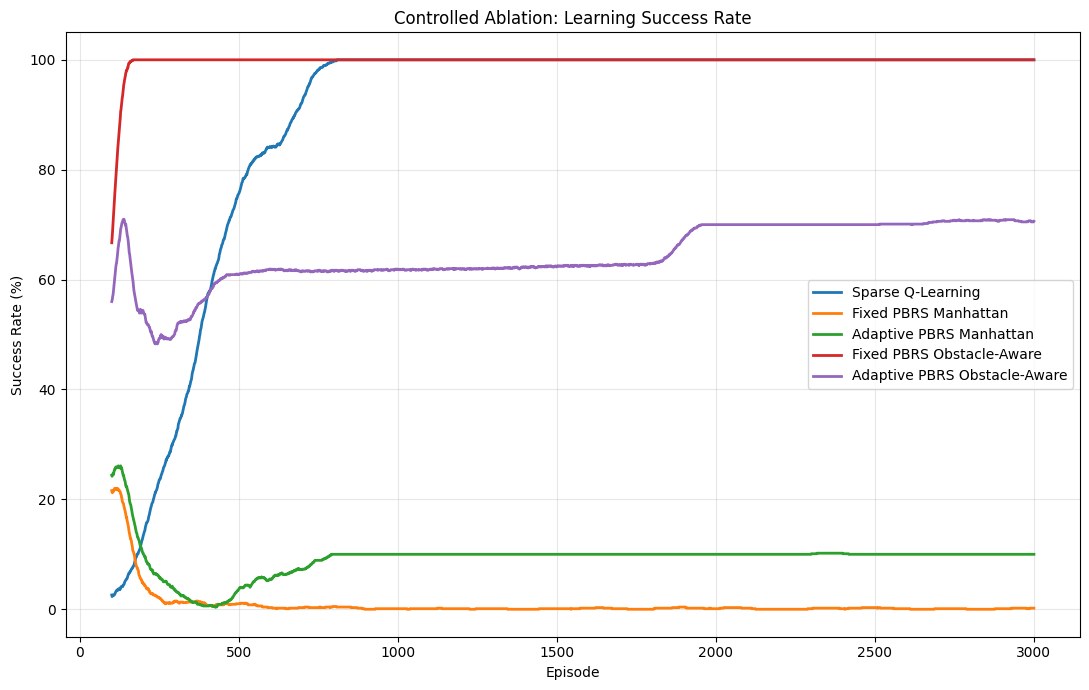

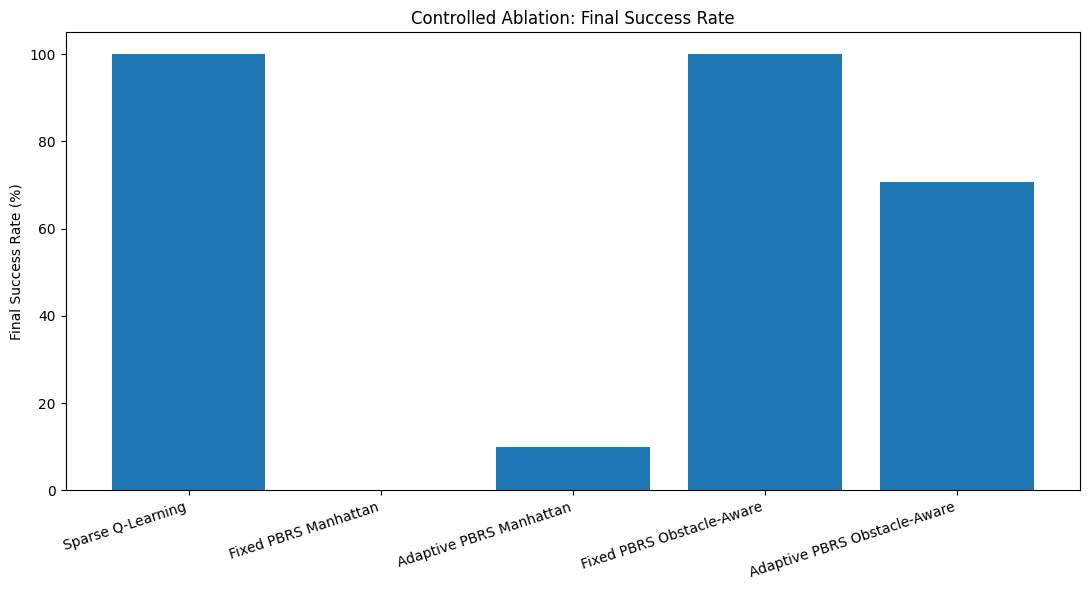

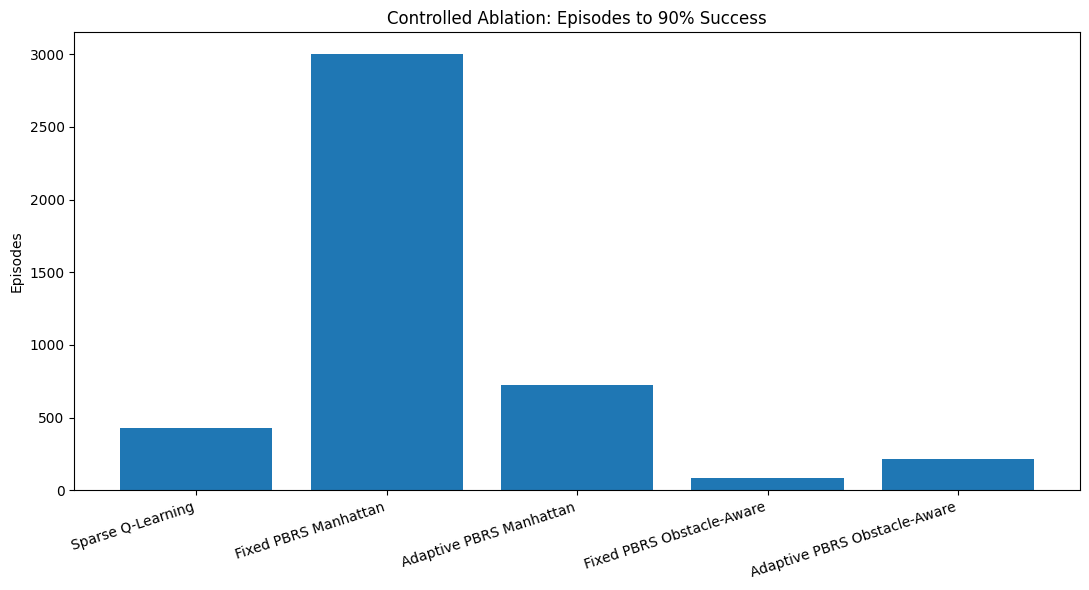

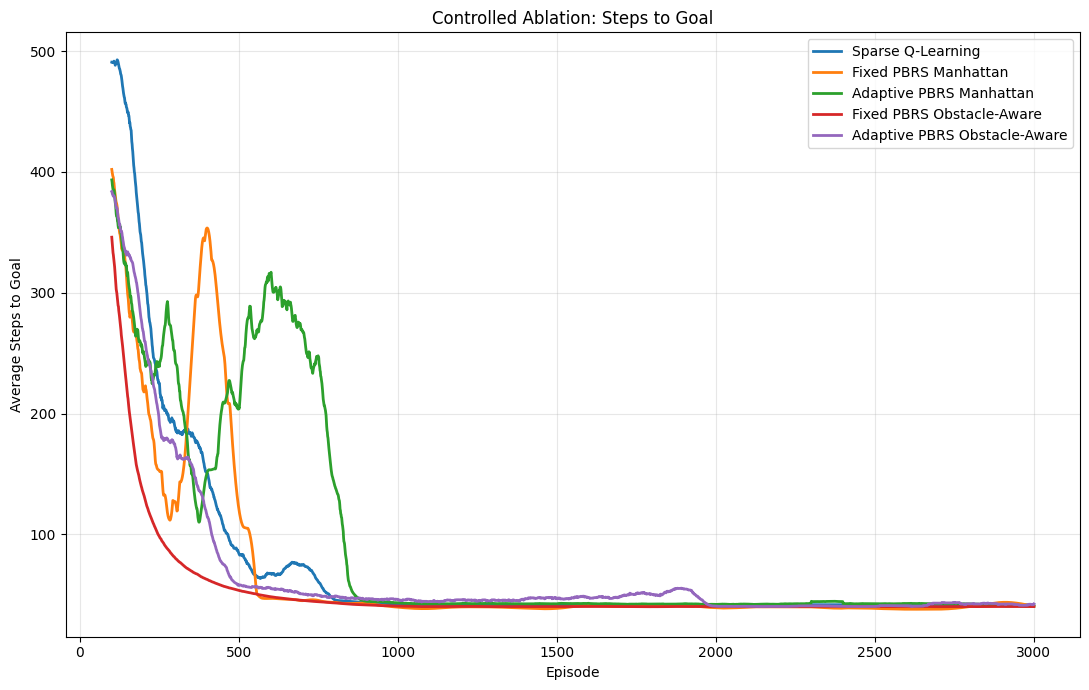

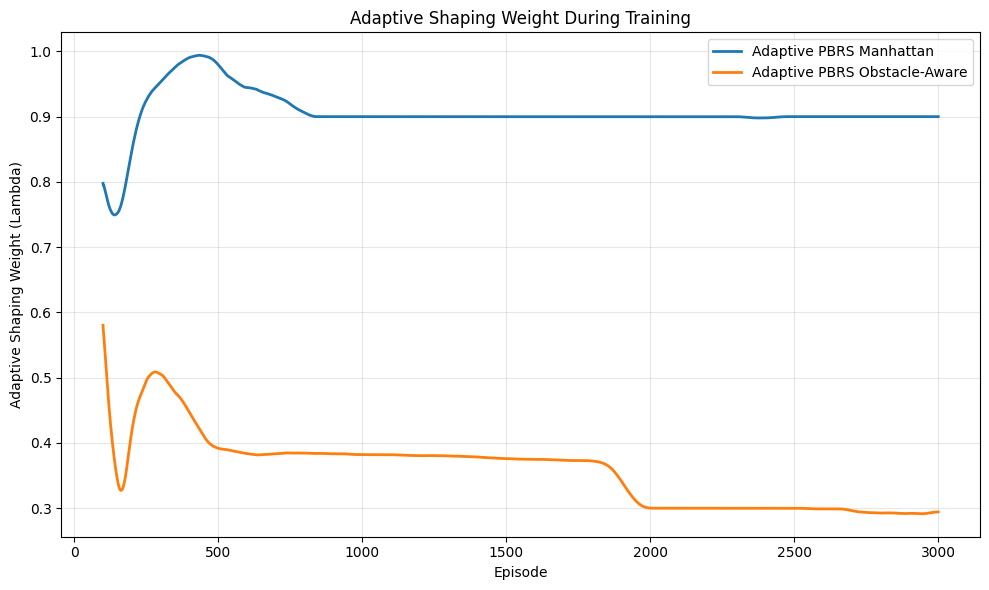

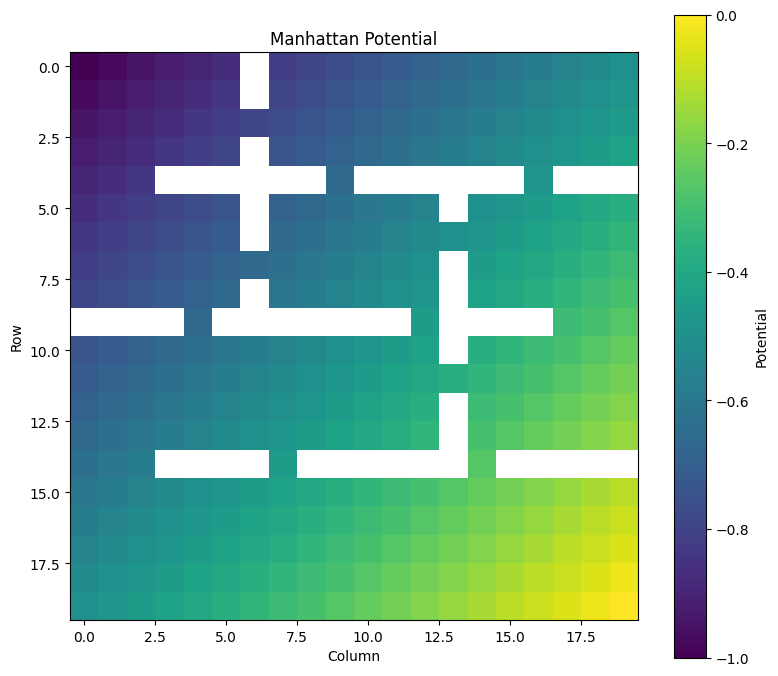

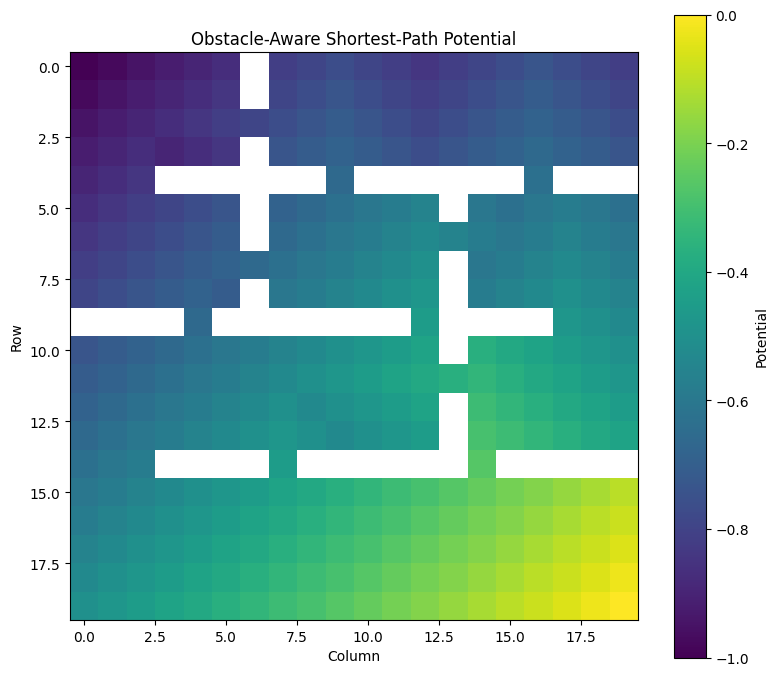


EXPERIMENT 5 COMPLETED

Total execution time: 25.79 minutes

FINAL TABLE:

                      Method  Final Success Rate (%)  Success SD  Average Steps to Goal  First Successful Episode  Seeds Reaching 90%  Episodes to 90% Success
           Sparse Q-Learning                  100.00        0.00                  41.69                      42.1                  10                   430.60
        Fixed PBRS Manhattan                    0.15        0.47                  41.67                       9.3                   0                      NaN
     Adaptive PBRS Manhattan                   10.00       31.62                  40.65                       9.3                   1                   727.00
   Fixed PBRS Obstacle-Aware                  100.00        0.00                  40.25                       9.1                  10                    86.10
Adaptive PBRS Obstacle-Aware                   70.70       47.22                  68.78                       9.1                

In [ ]:
+# ================================================================
# EXPERIMENT 5 — ROTATED-OBSTACLE CONTROLLED ABLATION STUDY
#
# Sparse Q-Learning vs:
# 1. Fixed PBRS + Manhattan Potential
# 2. Adaptive PBRS + Manhattan Potential
# 3. Fixed PBRS + Obstacle-Aware Potential
# 4. Adaptive PBRS + Obstacle-Aware Potential
#
# SAME environment, training budget and hyperparameters for ALL.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
import time

# ================================================================
# 1. REPRODUCIBLE ENVIRONMENT
# ================================================================

GRID = 20
START = (0, 0)
GOAL = (19, 19)

OBSTACLES = set()

# Vertical wall 1
for r in range(0, 17):
    if r not in [3, 10]:
        OBSTACLES.add((r, 4))

# Vertical wall 2
for r in range(3, 20):
    if r not in [7, 15]:
        OBSTACLES.add((r, 9))

# Vertical wall 3
for r in range(0, 17):
    if r not in [5, 12]:
        OBSTACLES.add((r, 14))

# Horizontal wall 1
for c in range(4, 15):
    if c not in [6, 11]:
        OBSTACLES.add((6, c))

# Horizontal wall 2
for c in range(0, 10):
    if c not in [2, 7]:
        OBSTACLES.add((13, c))

OBSTACLES.discard(START)
OBSTACLES.discard(GOAL)

# EXPERIMENT 5: rotate ONLY the original obstacles clockwise by 90 degrees.
# Keep START, GOAL, actions, algorithms and all training settings unchanged.
ORIGINAL_OBSTACLES = set(OBSTACLES)
OBSTACLES = {(c, GRID - 1 - r) for r, c in ORIGINAL_OBSTACLES}

# Do not silently remove blocked start/goal: reject an invalid rotated map.
assert len(OBSTACLES) == len(ORIGINAL_OBSTACLES)
assert START not in OBSTACLES, "Rotated obstacles block START"
assert GOAL not in OBSTACLES, "Rotated obstacles block GOAL"
print("Experiment 5: 90-degree clockwise obstacle rotation")
print("Obstacle count (before/after):", len(ORIGINAL_OBSTACLES), len(OBSTACLES))


ACTIONS = [
    (-1, 0),   # Up
    (1, 0),    # Down
    (0, -1),   # Left
    (0, 1)     # Right
]

# ================================================================
# 2. CONTROLLED TRAINING PARAMETERS
# ================================================================

N_EPISODES = 3000
N_SEEDS = 10
MAX_STEPS = 600

ALPHA = 0.10
GAMMA = 0.99

EPS_START = 1.0
EPS_MIN = 0.05
EPS_DECAY = 0.997

LAMBDA0 = 1.0
SUCCESS_WINDOW = 50

PLOT_WINDOW = 100
FINAL_WINDOW = 200

# ================================================================
# 3. ENVIRONMENT
# ================================================================

def environment_step(state, action):

    dr, dc = ACTIONS[action]

    nr = state[0] + dr
    nc = state[1] + dc

    # Invalid boundary move
    if nr < 0 or nr >= GRID or nc < 0 or nc >= GRID:
        return state, 0.0, False

    next_state = (nr, nc)

    # Obstacle collision
    if next_state in OBSTACLES:
        return state, 0.0, False

    # Goal
    if next_state == GOAL:
        return next_state, 1.0, True

    # Truly sparse reward
    return next_state, 0.0, False


# ================================================================
# 4. MANHATTAN POTENTIAL
# ================================================================

def manhattan_phi(state):

    distance = (
        abs(state[0] - GOAL[0])
        +
        abs(state[1] - GOAL[1])
    )

    max_distance = 2 * (GRID - 1)

    return -distance / max_distance


# ================================================================
# 5. COMPUTE TRUE OBSTACLE-AWARE DISTANCES USING BFS
# ================================================================

def compute_shortest_distances():

    distances = {GOAL: 0}

    queue = deque([GOAL])

    while queue:

        current = queue.popleft()

        for dr, dc in ACTIONS:

            nr = current[0] + dr
            nc = current[1] + dc

            if nr < 0 or nr >= GRID:
                continue

            if nc < 0 or nc >= GRID:
                continue

            state = (nr, nc)

            if state in OBSTACLES:
                continue

            if state not in distances:

                distances[state] = (
                    distances[current] + 1
                )

                queue.append(state)

    return distances


SHORTEST_DISTANCE = compute_shortest_distances()

if START not in SHORTEST_DISTANCE:
    raise ValueError("No path exists from START to GOAL.")

MAX_SHORTEST_DISTANCE = max(
    SHORTEST_DISTANCE.values()
)


def obstacle_phi(state):

    if state not in SHORTEST_DISTANCE:
        return -1.0

    return (
        -SHORTEST_DISTANCE[state]
        /
        MAX_SHORTEST_DISTANCE
    )


print("Environment check")
print("-----------------")
print("Grid:", GRID, "x", GRID)
print("Start:", START)
print("Goal:", GOAL)
print("Obstacles:", len(OBSTACLES))
print(
    "Shortest valid path:",
    SHORTEST_DISTANCE[START],
    "steps"
)


# ================================================================
# 6. FIVE METHODS
# ================================================================

methods = [

    "Sparse Q-Learning",

    "Fixed PBRS Manhattan",

    "Adaptive PBRS Manhattan",

    "Fixed PBRS Obstacle-Aware",

    "Adaptive PBRS Obstacle-Aware"
]


# ================================================================
# 7. TRAINING FUNCTION
# ================================================================

def train(method, seed):

    rng = np.random.default_rng(seed)

    Q = np.zeros(
        (GRID, GRID, 4),
        dtype=np.float64
    )

    success_history = np.zeros(N_EPISODES)

    steps_history = np.full(
        N_EPISODES,
        np.nan
    )

    lambda_history = np.zeros(N_EPISODES)

    epsilon = EPS_START

    for episode in range(N_EPISODES):

        state = START

        # --------------------------------------------------------
        # SHAPING WEIGHT
        # --------------------------------------------------------

        if method == "Sparse Q-Learning":

            lam = 0.0

        elif method in [
            "Fixed PBRS Manhattan",
            "Fixed PBRS Obstacle-Aware"
        ]:

            lam = LAMBDA0

        else:

            if episode == 0:
                recent_success = 0.0

            else:

                beginning = max(
                    0,
                    episode - SUCCESS_WINDOW
                )

                recent_success = np.mean(
                    success_history[
                        beginning:episode
                    ]
                )

            # Performance-adaptive shaping
            lam = (
                LAMBDA0
                *
                (1.0 - recent_success)
            )

        lambda_history[episode] = lam

        # --------------------------------------------------------
        # EPISODE
        # --------------------------------------------------------

        for step_number in range(MAX_STEPS):

            # Epsilon greedy
            if rng.random() < epsilon:

                action = rng.integers(4)

            else:

                q_values = Q[
                    state[0],
                    state[1]
                ]

                best_actions = np.flatnonzero(
                    q_values == q_values.max()
                )

                action = rng.choice(
                    best_actions
                )

            next_state, env_reward, done = (
                environment_step(
                    state,
                    action
                )
            )

            # ----------------------------------------------------
            # LEARNING REWARD
            # ----------------------------------------------------

            if method == "Sparse Q-Learning":

                learning_reward = env_reward

            else:

                if "Obstacle-Aware" in method:

                    current_phi = obstacle_phi(state)

                    next_phi = obstacle_phi(
                        next_state
                    )

                else:

                    current_phi = manhattan_phi(
                        state
                    )

                    next_phi = manhattan_phi(
                        next_state
                    )

                shaping_reward = (
                    GAMMA * next_phi
                    -
                    current_phi
                )

                learning_reward = (
                    env_reward
                    +
                    lam * shaping_reward
                )

            # ----------------------------------------------------
            # Q-LEARNING UPDATE
            # ----------------------------------------------------

            if done:

                target = learning_reward

            else:

                target = (
                    learning_reward
                    +
                    GAMMA
                    *
                    np.max(
                        Q[
                            next_state[0],
                            next_state[1]
                        ]
                    )
                )

            old_q = Q[
                state[0],
                state[1],
                action
            ]

            Q[
                state[0],
                state[1],
                action
            ] = (
                old_q
                +
                ALPHA
                *
                (target - old_q)
            )

            state = next_state

            if done:

                success_history[episode] = 1.0

                steps_history[episode] = (
                    step_number + 1
                )

                break

        epsilon = max(
            EPS_MIN,
            epsilon * EPS_DECAY
        )

    return {
        "success": success_history,
        "steps": steps_history,
        "lambda": lambda_history
    }


# ================================================================
# 8. RUN ALL METHODS
# ================================================================

all_results = {}

experiment_start = time.time()

print("\n" + "=" * 75)
print("EXPERIMENT 5 STARTED")
print("=" * 75)


for method in methods:

    print("\nTraining:", method)

    method_start = time.time()

    runs = []

    for seed in range(N_SEEDS):

        seed_start = time.time()

        result = train(
            method,
            seed
        )

        runs.append(result)

        seed_time = (
            time.time()
            -
            seed_start
        )

        print(
            f" Seed {seed+1}/{N_SEEDS}"
            f" completed in {seed_time:.1f} sec"
        )

    all_results[method] = {

        "success":
            np.vstack([
                run["success"]
                for run in runs
            ]),

        "steps":
            np.vstack([
                run["steps"]
                for run in runs
            ]),

        "lambda":
            np.vstack([
                run["lambda"]
                for run in runs
            ])
    }

    print(
        method,
        "completed in",
        round(
            time.time() - method_start,
            1
        ),
        "seconds."
    )


# ================================================================
# 9. CALCULATE FINAL RESULTS
# ================================================================

rows = []

seed_level_rows = []


for method in methods:

    data = all_results[method]

    final_success_per_seed = (
        np.mean(
            data["success"][:, -FINAL_WINDOW:],
            axis=1
        )
        *
        100
    )

    average_steps_per_seed = []

    convergence_per_seed = []

    first_success_per_seed = []


    for seed in range(N_SEEDS):

        # --------------------------------------------------------
        # Final successful steps
        # --------------------------------------------------------

        final_steps = (
            data["steps"][
                seed,
                -FINAL_WINDOW:
            ]
        )

        valid_steps = final_steps[
            ~np.isnan(final_steps)
        ]

        if len(valid_steps) > 0:

            avg_steps = np.mean(
                valid_steps
            )

        else:

            avg_steps = np.nan

        average_steps_per_seed.append(
            avg_steps
        )


        # --------------------------------------------------------
        # First successful episode
        # --------------------------------------------------------

        successes = (
            data["success"][seed]
        )

        success_locations = np.where(
            successes == 1
        )[0]

        if len(success_locations) > 0:

            first_success = (
                success_locations[0] + 1
            )

        else:

            first_success = np.nan

        first_success_per_seed.append(
            first_success
        )


        # --------------------------------------------------------
        # Episodes to >= 90% rolling success
        # --------------------------------------------------------

        rolling = (
            pd.Series(successes)
            .rolling(SUCCESS_WINDOW)
            .mean()
        )

        reached = np.where(
            rolling.values >= 0.90
        )[0]

        if len(reached) > 0:

            convergence = reached[0] + 1

        else:

            convergence = np.nan

        convergence_per_seed.append(
            convergence
        )


        seed_level_rows.append({

            "Method": method,

            "Seed": seed,

            "Final Success Rate (%)":
                final_success_per_seed[seed],

            "Average Steps to Goal":
                avg_steps,

            "First Successful Episode":
                first_success,

            "Episodes to 90% Success":
                convergence
        })


    average_steps_per_seed = np.array(
        average_steps_per_seed,
        dtype=float
    )

    convergence_per_seed = np.array(
        convergence_per_seed,
        dtype=float
    )

    first_success_per_seed = np.array(
        first_success_per_seed,
        dtype=float
    )

    number_reaching_90 = np.sum(
        ~np.isnan(
            convergence_per_seed
        )
    )


    rows.append({

        "Method":
            method,

        "Final Success Rate (%)":
            round(
                np.mean(
                    final_success_per_seed
                ),
                2
            ),

        "Success SD":
            round(
                np.std(
                    final_success_per_seed,
                    ddof=1
                ),
                2
            ),

        "Average Steps to Goal":
            round(
                np.nanmean(
                    average_steps_per_seed
                ),
                2
            )
            if np.any(
                ~np.isnan(
                    average_steps_per_seed
                )
            )
            else np.nan,

        "First Successful Episode":
            round(
                np.nanmean(
                    first_success_per_seed
                ),
                2
            )
            if np.any(
                ~np.isnan(
                    first_success_per_seed
                )
            )
            else np.nan,

        "Seeds Reaching 90%":
            int(
                number_reaching_90
            ),

        "Episodes to 90% Success":
            round(
                np.nanmean(
                    convergence_per_seed
                ),
                2
            )
            if number_reaching_90 > 0
            else np.nan
    })


summary = pd.DataFrame(rows)

seed_results = pd.DataFrame(
    seed_level_rows
)


# ================================================================
# 10. FINAL TABLE
# ================================================================

print("\n" + "=" * 100)

print("ROTATED-OBSTACLE CONTROLLED ABLATION RESULTS")

print("=" * 100)

display(summary)


# ================================================================
# 11. MOVING AVERAGE
# ================================================================

def moving_average(data, window):

    return np.convolve(
        data,
        np.ones(window) / window,
        mode="valid"
    )


x = np.arange(
    PLOT_WINDOW,
    N_EPISODES + 1
)


# ================================================================
# 12. SUCCESS-RATE LEARNING CURVES
# ================================================================

plt.figure(figsize=(11, 7))


for method in methods:

    mean_success = (
        np.mean(
            all_results[method]["success"],
            axis=0
        )
        *
        100
    )

    smoothed = moving_average(
        mean_success,
        PLOT_WINDOW
    )

    plt.plot(
        x,
        smoothed,
        label=method,
        linewidth=2
    )


plt.xlabel("Episode")

plt.ylabel(
    "Success Rate (%)"
)

plt.title(
    "Controlled Ablation: Learning Success Rate"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "exp5_success_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 13. FINAL SUCCESS RATE
# ================================================================

plt.figure(figsize=(11, 6))

plt.bar(
    summary["Method"],
    summary["Final Success Rate (%)"]
)

plt.ylabel(
    "Final Success Rate (%)"
)

plt.title(
    "Controlled Ablation: Final Success Rate"
)

plt.ylim(0, 105)

plt.xticks(
    rotation=18,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "exp5_final_success.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 14. CONVERGENCE GRAPH
# ================================================================

convergence_plot = (
    summary[
        "Episodes to 90% Success"
    ]
    .fillna(N_EPISODES)
)


plt.figure(figsize=(11, 6))

plt.bar(
    summary["Method"],
    convergence_plot
)

plt.ylabel(
    "Episodes"
)

plt.title(
    "Controlled Ablation: Episodes to 90% Success"
)

plt.xticks(
    rotation=18,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    "exp5_convergence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 15. STEPS TO GOAL
# ================================================================

plt.figure(figsize=(11, 7))


for method in methods:

    matrix = (
        all_results[method]["steps"]
    )

    mean_steps = []

    for episode in range(N_EPISODES):

        values = matrix[:, episode]

        valid = values[
            ~np.isnan(values)
        ]

        if len(valid) > 0:

            mean_steps.append(
                np.mean(valid)
            )

        else:

            mean_steps.append(
                np.nan
            )

    mean_steps = np.array(
        mean_steps
    )

    # Used only for visualization
    mean_steps = (
        pd.Series(mean_steps)
        .interpolate(
            limit_direction="both"
        )
        .to_numpy()
    )

    smoothed = moving_average(
        mean_steps,
        PLOT_WINDOW
    )

    plt.plot(
        x,
        smoothed,
        label=method,
        linewidth=2
    )


plt.xlabel("Episode")

plt.ylabel(
    "Average Steps to Goal"
)

plt.title(
    "Controlled Ablation: Steps to Goal"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "exp5_steps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 16. ADAPTIVE LAMBDA
# ================================================================

plt.figure(figsize=(10, 6))


for method in [
    "Adaptive PBRS Manhattan",
    "Adaptive PBRS Obstacle-Aware"
]:

    mean_lambda = np.mean(
        all_results[method]["lambda"],
        axis=0
    )

    smooth_lambda = moving_average(
        mean_lambda,
        PLOT_WINDOW
    )

    plt.plot(
        x,
        smooth_lambda,
        label=method,
        linewidth=2
    )


plt.xlabel("Episode")

plt.ylabel(
    "Adaptive Shaping Weight (Lambda)"
)

plt.title(
    "Adaptive Shaping Weight During Training"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "exp5_lambda.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 17. POTENTIAL MAPS
# ================================================================

manhattan_map = np.full(
    (GRID, GRID),
    np.nan
)

obstacle_map = np.full(
    (GRID, GRID),
    np.nan
)


for r in range(GRID):

    for c in range(GRID):

        state = (r, c)

        if state not in OBSTACLES:

            manhattan_map[r, c] = (
                manhattan_phi(state)
            )

            obstacle_map[r, c] = (
                obstacle_phi(state)
            )


plt.figure(figsize=(8, 7))

plt.imshow(manhattan_map)

plt.colorbar(
    label="Potential"
)

plt.title(
    "Manhattan Potential"
)

plt.xlabel("Column")

plt.ylabel("Row")

plt.tight_layout()

plt.savefig(
    "exp5_manhattan_potential.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


plt.figure(figsize=(8, 7))

plt.imshow(obstacle_map)

plt.colorbar(
    label="Potential"
)

plt.title(
    "Obstacle-Aware Shortest-Path Potential"
)

plt.xlabel("Column")

plt.ylabel("Row")

plt.tight_layout()

plt.savefig(
    "exp5_obstacle_potential.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ================================================================
# 18. SAVE RESULTS
# ================================================================

summary.to_csv(
    "experiment5_summary.csv",
    index=False
)

seed_results.to_csv(
    "experiment5_seed_results.csv",
    index=False
)


# ================================================================
# 19. FINAL PRINT
# ================================================================

total_time = (
    time.time()
    -
    experiment_start
)


print("\n" + "=" * 100)

print("EXPERIMENT 5 COMPLETED")

print("=" * 100)


print(
    "\nTotal execution time:",
    round(
        total_time / 60,
        2
    ),
    "minutes"
)


print("\nFINAL TABLE:\n")

print(
    summary.to_string(
        index=False
    )
)


print("\nGenerated files:")

print("1. experiment5_summary.csv")
print("2. experiment5_seed_results.csv")
print("3. exp5_success_rate.png")
print("4. exp5_final_success.png")
print("5. exp5_convergence.png")
print("6. exp5_steps.png")
print("7. exp5_lambda.png")
print("8. exp5_manhattan_potential.png")
print("9. exp5_obstacle_potential.png")


In [ ]:

# Download Experiment 5 CSV files

from google.colab import files

files.download("experiment5_summary.csv")
files.download("experiment5_seed_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>